In [2]:
# Load the data and validate the files
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Keep this notebook in the same folder as your project CSV files.
DATA_DIR = "."

X = pd.read_csv(os.path.join(DATA_DIR, "clients_features_processed.csv"))
client_ids = pd.read_csv(os.path.join(DATA_DIR, "client_ids_for_clustering.csv"))
clients = pd.read_csv(os.path.join(DATA_DIR, "clients_cleaned.csv"))
clustered = pd.read_csv(os.path.join(DATA_DIR, "kmeans_buyer_segments.csv"))

model_path = os.path.join(DATA_DIR, "kmeans_buyer_segmentation_model.joblib")
model = joblib.load(model_path)

assert len(X) == len(client_ids) == len(clients) == len(clustered)
assert client_ids["client_id"].is_unique
assert clustered["client_id"].is_unique

print("Processed features:", X.shape)
print("Customer records:", len(clients))
print("Feature columns:", X.shape[1])
print("Existing K-Means clusters:", sorted(clustered["cluster"].unique()))
print("All basic checks passed.")

Processed features: (2000, 80)
Customer records: 2000
Feature columns: 80
Existing K-Means clusters: [np.int64(0), np.int64(1)]
All basic checks passed.


Cluster means calculated: (2, 80)
                      encoded_feature  separation_score
          numeric__satisfaction_score          0.749039
                         numeric__age          0.000361
       categorical__region_California          0.000106
           categorical__region_Oregon          0.000049
             categorical__country_USA          0.000035
          categorical__region_Arizona          0.000024
 categorical__referral_channel_Client          0.000023
                categorical__gender_M          0.000020
                categorical__gender_F          0.000020
          categorical__country_Canada          0.000016
          categorical__region_Florida          0.000014
 categorical__region_Northern Ireland          0.000011
             categorical__region_Ohio          0.000011
         categorical__country_Denmark          0.000011
         categorical__region_Virginia          0.000010
categorical__referral_channel_Website          0.000009
         categ

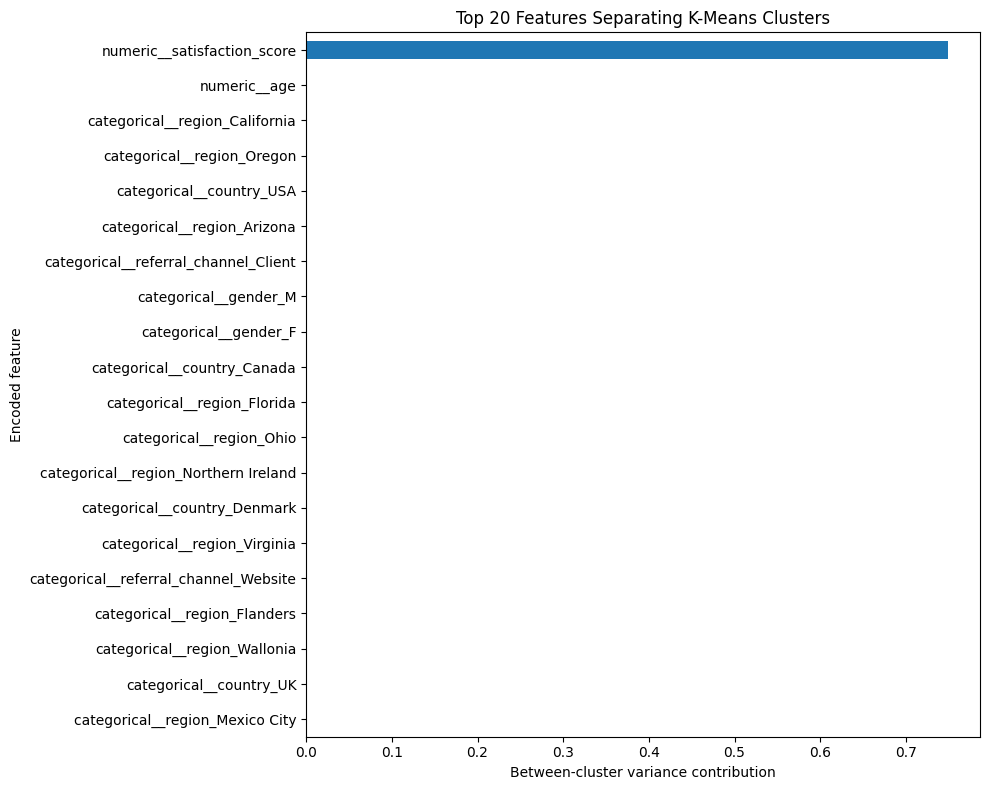

In [3]:
# Investigate which features contribute most to clustering
# Use the existing K-Means assignments
labels = clustered["cluster"].to_numpy()

assert len(labels) == len(X)

cluster_means = X.groupby(labels).mean()
print("Cluster means calculated:", cluster_means.shape)

# Measure how strongly each feature separates the clusters.
# This formula generalizes to two or more clusters.
overall_mean = X.mean(axis=0)
cluster_sizes = pd.Series(labels).value_counts(normalize=True)

between_cluster_variance = pd.Series(0.0, index=X.columns)

for cluster_id in cluster_means.index:
    weight = cluster_sizes.loc[cluster_id]
    between_cluster_variance += (
        weight * (cluster_means.loc[cluster_id] - overall_mean) ** 2
    )

feature_scores = (
    between_cluster_variance
    .sort_values(ascending=False)
    .rename("separation_score")
    .reset_index()
    .rename(columns={"index": "encoded_feature"})
)

print(feature_scores.head(20).to_string(index=False))

feature_scores.head(20).sort_values("separation_score").plot(
    x="encoded_feature",
    y="separation_score",
    kind="barh",
    figsize=(10, 8),
    legend=False
)
plt.title("Top 20 Features Separating K-Means Clusters")
plt.xlabel("Between-cluster variance contribution")
plt.ylabel("Encoded feature")
plt.tight_layout()
plt.show()

Feature contribution by original field:
original_feature
numeric__satisfaction_score    7.490394e-01
numeric__age                   3.606964e-04
region                         3.287980e-04
country                        9.452387e-05
gender                         3.999211e-05
referral_channel               3.541375e-05
client_type                    2.734299e-06
loan_applied                   1.458966e-06
acquisition_purpose            5.269126e-11


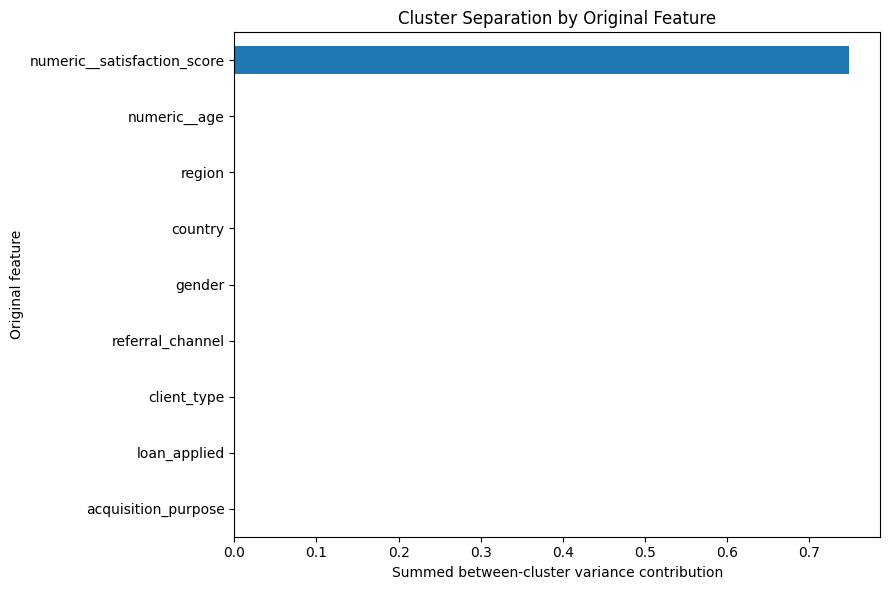

In [4]:
# Summarize the contributions by original feature
def get_source_feature(column):
    # Match the prefixes generated by your preprocessing pipeline.
    if column.startswith("categorical__"):
        name = column.replace("categorical__", "", 1)
        for field in [
            "client_type", "gender", "country", "region",
            "acquisition_purpose", "loan_applied", "referral_channel"
        ]:
            if name == field or name.startswith(field + "_"):
                return field
        return name

    if column.startswith("numerical__"):
        return column.replace("numerical__", "", 1)

    return column

feature_scores["original_feature"] = feature_scores["encoded_feature"].apply(
    get_source_feature
)

grouped_scores = (
    feature_scores.groupby("original_feature")["separation_score"]
    .sum()
    .sort_values(ascending=False)
)

print("Feature contribution by original field:")
print(grouped_scores.to_string())

grouped_scores.sort_values().plot(
    kind="barh", figsize=(9, 6), legend=False
)
plt.title("Cluster Separation by Original Feature")
plt.xlabel("Summed between-cluster variance contribution")
plt.ylabel("Original feature")
plt.tight_layout()
plt.show()

In [5]:
# Compare the customer profiles
profile = clients.merge(
    clustered[["client_id", "cluster"]],
    on="client_id",
    how="inner",
    validate="one_to_one"
)

# Use the same reference date as the original feature engineering.
profile["date_of_birth"] = pd.to_datetime(
    profile["date_of_birth"], errors="coerce"
)

reference_date = pd.Timestamp("2025-01-01")
profile["age"] = (
    reference_date.year
    - profile["date_of_birth"].dt.year
    - (
        (profile["date_of_birth"].dt.month > reference_date.month)
        | (
            (profile["date_of_birth"].dt.month == reference_date.month)
            & (profile["date_of_birth"].dt.day > reference_date.day)
        )
    ).astype("Int64")
)

print("Profile rows:", len(profile))
print("Rows per cluster:")
print(profile["cluster"].value_counts().sort_index())

Profile rows: 2000
Rows per cluster:
cluster
0     774
1    1226
Name: count, dtype: int64


In [6]:
# Numerical profile comparison
numeric_profile = profile.groupby("cluster").agg(
    customer_count=("client_id", "count"),
    average_age=("age", "mean"),
    median_age=("age", "median"),
    average_satisfaction=("satisfaction_score", "mean"),
    median_satisfaction=("satisfaction_score", "median")
).round(2)

print(numeric_profile)

         customer_count  average_age  median_age  average_satisfaction  \
cluster                                                                  
0                   774        53.69        54.0                  1.49   
1                  1226        54.36        55.0                  4.00   

         median_satisfaction  
cluster                       
0                        1.0  
1                        4.0  


In [7]:
# Categorical profile comparison
categorical_fields = [
    "country",
    "region",
    "client_type",
    "referral_channel",
    "acquisition_purpose",
    "loan_applied"
]

for field in categorical_fields:
    print(f"\n{'=' * 60}\n{field.upper()} BY CLUSTER")

    counts = pd.crosstab(
        profile["cluster"],
        profile[field],
        normalize="index"
    ).mul(100).round(1)

    print(counts.to_string())


COUNTRY BY CLUSTER
country  Australia  Belgium  Canada  Denmark  France  Germany  Mexico  Russia   UK   USA
cluster                                                                                 
0              2.1      2.5     3.7      1.2     2.5      2.5     1.7     1.9  4.4  77.6
1              1.9      2.0     4.6      0.5     2.8      3.0     2.2     1.7  5.0  76.4

REGION BY CLUSTER
region   Alberta  Arizona  Baja California  Bavaria  Berlin  British Columbia  Brittany  Brussels  California  Capital Region  Central Denmark  Colorado  England  Flanders  Florida  Georgia  Hamburg  Hesse  Ile-de-France  Jalisco  Kansas  Krasnodar Krai  Manitoba  Mexico City  Moscow Oblast  Nevada  New South Wales  New York  Normandy  North Denmark  North Rhine-Westphalia  Northern Ireland  Novosibirsk  Nuevo Leon  Occitanie  Ohio  Ontario  Oregon  Provence  Puebla  Quebec  Queensland  Saint Petersburg  Scotland  South Australia  Southern Denmark  Tatarstan  Texas  Utah  Victoria  Virginia  Wales 

 K   Inertia  Silhouette Score  Smallest Cluster Size  Largest Cluster Size
 2 9160.2890            0.1345                    774                  1226
 3 8213.7975            0.1206                    567                   718
 4 7674.8135            0.1046                    394                   605
 5 7343.2524            0.1024                    368                   453
 6 7047.1100            0.1011                    317                   351


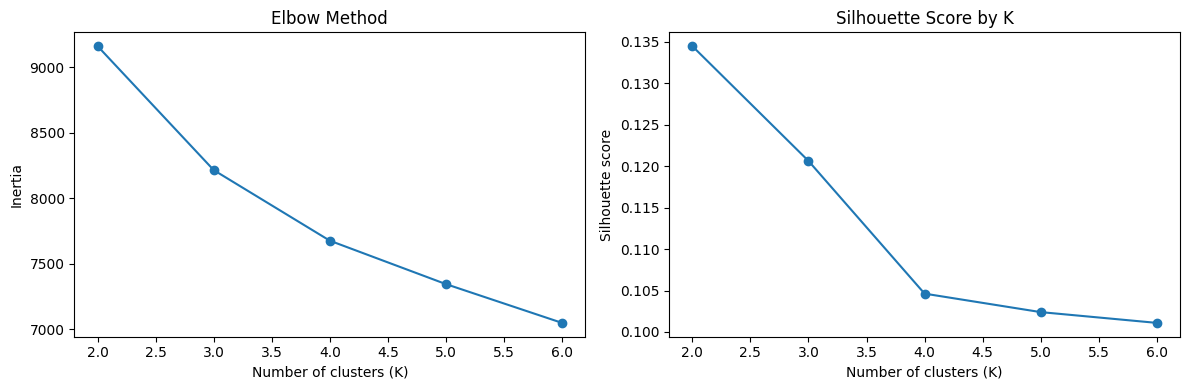

In [8]:
# Test whether two or four clusters are more useful
results = []

for k in range(2, 7):
    km = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )
    cluster_labels = km.fit_predict(X)

    results.append({
        "K": k,
        "Inertia": km.inertia_,
        "Silhouette Score": silhouette_score(X, cluster_labels),
        "Smallest Cluster Size": pd.Series(cluster_labels).value_counts().min(),
        "Largest Cluster Size": pd.Series(cluster_labels).value_counts().max()
    })

k_results = pd.DataFrame(results)
print(k_results.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(k_results["K"], k_results["Inertia"], marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of clusters (K)")
axes[0].set_ylabel("Inertia")

axes[1].plot(
    k_results["K"],
    k_results["Silhouette Score"],
    marker="o"
)
axes[1].set_title("Silhouette Score by K")
axes[1].set_xlabel("Number of clusters (K)")
axes[1].set_ylabel("Silhouette score")

plt.tight_layout()
plt.show()

In [9]:
# Compare K=2, K=3 and K=4 customer profiles
profile_comparisons = []

for k in [2, 3, 4]:
    km = KMeans(n_clusters=k, random_state=42, n_init=20)
    labels_k = km.fit_predict(X)

    temp = clients.copy()
    temp["cluster"] = labels_k

    counts = temp.groupby("cluster").size()
    purpose_pct = pd.crosstab(
        temp["cluster"],
        temp["acquisition_purpose"],
        normalize="index"
    ) * 100

    loan_pct = pd.crosstab(
        temp["cluster"],
        temp["loan_applied"],
        normalize="index"
    ) * 100

    satisfaction = temp.groupby("cluster")["satisfaction_score"].mean()

    print(f"\n{'=' * 55}\nK = {k}")
    print("Cluster sizes:")
    print(counts.to_string())
    print("\nAcquisition purpose (%):")
    print(purpose_pct.round(1).to_string())
    print("\nLoan status (%):")
    print(loan_pct.round(1).to_string())
    print("\nAverage satisfaction:")
    print(satisfaction.round(2).to_string())


K = 2
Cluster sizes:
cluster
0     774
1    1226

Acquisition purpose (%):
acquisition_purpose  Home  Investment
cluster                              
0                    69.3        30.7
1                    69.2        30.8

Loan status (%):
loan_applied    No   Yes
cluster                 
0             63.3  36.7
1             63.1  36.9

Average satisfaction:
cluster
0    1.49
1    4.00

K = 3
Cluster sizes:
cluster
0    715
1    567
2    718

Acquisition purpose (%):
acquisition_purpose  Home  Investment
cluster                              
0                    73.3        26.7
1                    66.7        33.3
2                    67.3        32.7

Loan status (%):
loan_applied    No   Yes
cluster                 
0             66.4  33.6
1             62.6  37.4
2             60.4  39.6

Average satisfaction:
cluster
0    3.20
1    1.43
2    4.13

K = 4
Cluster sizes:
cluster
0    578
1    423
2    605
3    394

Acquisition purpose (%):
acquisition_purpose  Home  Investm

In [10]:
# Test alternative feature representations
# Identify which encoded columns belong to each original categorical field.
categorical_fields = [
    "client_type", "gender", "country", "region",
    "acquisition_purpose", "loan_applied", "referral_channel"
]

feature_groups = {}

for field in categorical_fields:
    feature_groups[field] = [
        col for col in X.columns
        if col.startswith(f"categorical__{field}_")
    ]

# Representation A: existing features
X_original = X.copy()

# Representation B: weight each categorical field as a block.
# A field with many encoded columns gets less weight per column.
X_weighted = X.copy()

for field, cols in feature_groups.items():
    if cols:
        X_weighted.loc[:, cols] = (
            X_weighted[cols] / np.sqrt(len(cols))
        )

# Representation C: remove region's one-hot columns
region_cols = feature_groups["region"]
X_no_region = X.drop(columns=region_cols).copy()

representations = {
    "Original 80 features": X_original,
    "Categorical block-weighted": X_weighted,
    "Without region features": X_no_region
}

representation_results = []

for name, X_variant in representations.items():
    for k in [2, 3, 4]:
        km = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=20
        )
        labels_variant = km.fit_predict(X_variant)

        representation_results.append({
            "Representation": name,
            "K": k,
            "Silhouette Score": silhouette_score(
                X_variant, labels_variant
            ),
            "Smallest Cluster Size": pd.Series(
                labels_variant
            ).value_counts().min()
        })

representation_results = pd.DataFrame(representation_results)

print(
    representation_results.sort_values(
        ["K", "Silhouette Score"],
        ascending=[True, False]
    ).round(4).to_string(index=False)
)

representation_results.to_csv(
    "alternative_representation_comparison.csv",
    index=False
)

            Representation  K  Silhouette Score  Smallest Cluster Size
Categorical block-weighted  2            0.2311                    774
   Without region features  2            0.1573                    942
      Original 80 features  2            0.1345                    774
Categorical block-weighted  3            0.2221                    575
   Without region features  3            0.1483                    568
      Original 80 features  3            0.1206                    567
Categorical block-weighted  4            0.2087                    387
   Without region features  4            0.1319                    392
      Original 80 features  4            0.1046                    394


In [11]:
# Validate the saved K-Means model
# Reload the saved model
loaded_model = joblib.load(
    "kmeans_buyer_segmentation_model.joblib"
)

# Check the exact feature count
expected_features = getattr(
    loaded_model, "n_features_in_", None
)

print("Features in CSV:", X.shape[1])
print("Features expected by model:", expected_features)

assert expected_features == X.shape[1], (
    "Feature count mismatch. Check preprocessing and feature selection."
)

# Predict clusters using the original processed feature matrix
predicted_labels = loaded_model.predict(X)

predicted = pd.DataFrame({
    "client_id": client_ids["client_id"],
    "predicted_cluster": predicted_labels
})

saved = clustered[["client_id", "cluster"]].rename(
    columns={"cluster": "saved_cluster"}
)

comparison = predicted.merge(
    saved,
    on="client_id",
    how="inner",
    validate="one_to_one"
)

assert len(comparison) == len(X)

# K-Means cluster labels can be permuted, so compare assignments
# pairwise rather than requiring cluster numbers to match exactly.
from sklearn.metrics import adjusted_rand_score

ari = adjusted_rand_score(
    comparison["saved_cluster"],
    comparison["predicted_cluster"]
)

print("Rows validated:", len(comparison))
print("Adjusted Rand Index:", round(ari, 6))
print("Cluster counts from reloaded model:")
print(pd.Series(predicted_labels).value_counts().sort_index())

if ari == 1.0:
    print("PASS: The reloaded model reproduces the saved clustering.")
else:
    print("CHECK: Assignments differ; investigate data order or model version.")

Features in CSV: 80
Features expected by model: 80
Rows validated: 2000
Adjusted Rand Index: 1.0
Cluster counts from reloaded model:
0     774
1    1226
Name: count, dtype: int64
PASS: The reloaded model reproduces the saved clustering.


In [14]:
# Validate the preprocessing pipeline
preprocessor = joblib.load(
    "buyer_segmentation_preprocessor.joblib"
)

# Recreate the feature input using the fields used in Step 3.
categorical_cols = [
    "client_type", "gender", "country", "region",
    "acquisition_purpose", "loan_applied", "referral_channel"
]
numeric_cols = ["age", "satisfaction_score"]

raw = clients.copy()
raw["date_of_birth"] = pd.to_datetime(
    raw["date_of_birth"], errors="coerce"
)

ref_date = pd.Timestamp("2025-01-01")
raw["age"] = (
    ref_date.year - raw["date_of_birth"].dt.year
    - (
        (raw["date_of_birth"].dt.month > ref_date.month)
        | (
            (raw["date_of_birth"].dt.month == ref_date.month)
            & (raw["date_of_birth"].dt.day > ref_date.day)
        )
    ).astype("Int64")
)

X_raw = raw[categorical_cols + numeric_cols]

X_rebuilt_array = preprocessor.transform(X_raw)

# Convert sparse matrix to dense array if necessary
if hasattr(X_rebuilt_array, "toarray"):
    X_rebuilt_array = X_rebuilt_array.toarray()
elif hasattr(X_rebuilt_array, "todense"):
    X_rebuilt_array = np.asarray(X_rebuilt_array.todense())

# Obtain output feature names and compare against the saved CSV.
rebuilt_names = preprocessor.get_feature_names_out()
X_rebuilt = pd.DataFrame(
    X_rebuilt_array,
    columns=rebuilt_names
)

print("Rebuilt feature shape:", X_rebuilt.shape)
print("Saved feature shape:", X.shape)

assert list(X_rebuilt.columns) == list(X.columns), (
    "Feature names or order differ. Do not use the rebuilt matrix "
    "for prediction until the mismatch is resolved."
)

max_difference = np.max(
    np.abs(
        X_rebuilt.to_numpy(dtype=float)
        - X.to_numpy(dtype=float)
    )
)

print("Maximum absolute feature difference:", max_difference)

if np.allclose(X_rebuilt, X, atol=1e-6):
    print("PASS: Preprocessing reproduces the saved features.")
else:
    print("CHECK: Preprocessing differs from the saved feature matrix.")

Rebuilt feature shape: (2000, 80)
Saved feature shape: (2000, 80)
Maximum absolute feature difference: 4.440892098500626e-16
PASS: Preprocessing reproduces the saved features.


In [15]:
# Save your validation report
summary = {
    "customer_count": len(clients),
    "feature_count": X.shape[1],
    "original_kmeans_clusters": len(np.unique(labels)),
    "saved_model_feature_count": expected_features,
    "saved_model_ari": ari,
    "preprocessing_max_difference": float(max_difference),
    "preprocessing_matches": bool(
        np.allclose(X_rebuilt, X, atol=1e-6)
    )
}

pd.DataFrame([summary]).to_csv(
    "clustering_validation_summary.csv",
    index=False
)

print(pd.DataFrame([summary]).to_string(index=False))
print("Saved: clustering_validation_summary.csv")

 customer_count  feature_count  original_kmeans_clusters  saved_model_feature_count  saved_model_ari  preprocessing_max_difference  preprocessing_matches
           2000             80                         2                         80              1.0                  4.440892e-16                   True
Saved: clustering_validation_summary.csv


In [16]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Check the current folder
print("Current folder:", os.getcwd())

# Check whether the required files exist
required_files = [
    "clients_features_processed.csv",
    "client_ids_for_clustering.csv",
    "clients_cleaned.csv",
    "kmeans_buyer_segments.csv",
    "kmeans_buyer_segmentation_model.joblib",
    "buyer_segmentation_preprocessor.joblib"
]

for file in required_files:
    if os.path.exists(file):
        print("FOUND:", file)
    else:
        print("MISSING:", file)

Current folder: /content
FOUND: clients_features_processed.csv
FOUND: client_ids_for_clustering.csv
FOUND: clients_cleaned.csv
FOUND: kmeans_buyer_segments.csv
FOUND: kmeans_buyer_segmentation_model.joblib
FOUND: buyer_segmentation_preprocessor.joblib


In [18]:
# Step 2 — Load the data and check the customer records.
import pandas as pd
import joblib
import numpy as np

# Load the datasets
X = pd.read_csv("clients_features_processed.csv")
client_ids = pd.read_csv("client_ids_for_clustering.csv")
clients = pd.read_csv("clients_cleaned.csv")
clustered = pd.read_csv("kmeans_buyer_segments.csv")

# Load the trained K-Means model
model = joblib.load("kmeans_buyer_segmentation_model.joblib")

# Display dataset information
print("Processed features shape:", X.shape)
print("Client IDs shape:", client_ids.shape)
print("Original customer data shape:", clients.shape)
print("Clustered customer data shape:", clustered.shape)

print("\nFeature columns:")
print(X.columns.tolist())

print("\nExisting cluster counts:")
print(clustered["cluster"].value_counts().sort_index())

print("\nFirst five customer records:")
display(clustered.head())

Processed features shape: (2000, 80)
Client IDs shape: (2000, 1)
Original customer data shape: (2000, 12)
Clustered customer data shape: (2000, 13)

Feature columns:
['categorical__client_type_Company', 'categorical__client_type_Individual', 'categorical__gender_F', 'categorical__gender_M', 'categorical__country_Australia', 'categorical__country_Belgium', 'categorical__country_Canada', 'categorical__country_Denmark', 'categorical__country_France', 'categorical__country_Germany', 'categorical__country_Mexico', 'categorical__country_Russia', 'categorical__country_UK', 'categorical__country_USA', 'categorical__region_Alberta', 'categorical__region_Arizona', 'categorical__region_Baja California', 'categorical__region_Bavaria', 'categorical__region_Berlin', 'categorical__region_British Columbia', 'categorical__region_Brittany', 'categorical__region_Brussels', 'categorical__region_California', 'categorical__region_Capital Region', 'categorical__region_Central Denmark', 'categorical__region_C

,client_id,client_type,first_name,last_name,date_of_birth,gender,country,region,acquisition_purpose,satisfaction_score,loan_applied,referral_channel,cluster
0,C0001,Individual,Kareem,Liu,1968-05-11,F,USA,California,Home,4,Yes,Website,1
1,C0002,Individual,Trystan,Oconnor,1962-11-26,M,USA,California,Home,1,No,Website,0
2,C0003,Individual,Kale,Gay,1959-04-07,M,USA,California,Home,4,Yes,Agency,1
3,C0004,Individual,Russell,Gross,1959-11-25,M,USA,California,Home,5,No,Website,1
4,C0005,Company,Marleez,Co,1976-02-28,M,USA,California,Investment,5,No,Website,1


In [19]:
# Step 3.1: Calculate feature contributions to clustering

# Get the existing K-Means cluster labels
labels = clustered["cluster"].to_numpy()

# Verify that rows match
assert len(X) == len(labels), (
    "Error: The number of feature rows and cluster labels differs."
)

# Calculate the overall mean of each processed feature
overall_mean = X.mean(axis=0)

# Calculate the mean of each feature within each cluster
cluster_means = X.groupby(labels).mean()

# Calculate the proportion of customers in each cluster
cluster_sizes = pd.Series(labels).value_counts(normalize=True)

# Calculate between-cluster variance for each feature
between_variance = pd.Series(0.0, index=X.columns)

for cluster_id in cluster_means.index:
    weight = cluster_sizes.loc[cluster_id]

    between_variance += (
        weight *
        (cluster_means.loc[cluster_id] - overall_mean) ** 2
    )

# Sort features from highest to lowest contribution
feature_importance = (
    between_variance
    .sort_values(ascending=False)
    .reset_index()
)

feature_importance.columns = [
    "Feature",
    "Separation_Score"
]

# Calculate percentage contribution across the measured features
total_score = feature_importance["Separation_Score"].sum()

feature_importance["Contribution_Percent"] = (
    feature_importance["Separation_Score"] / total_score * 100
    if total_score > 0
    else 0
)

print("TOP 20 FEATURES CONTRIBUTING TO CLUSTER SEPARATION")
display(feature_importance.head(20).round(4))

# Save the results
feature_importance.to_csv(
    "feature_contribution_analysis.csv",
    index=False
)

print("Saved: feature_contribution_analysis.csv")

TOP 20 FEATURES CONTRIBUTING TO CLUSTER SEPARATION


,Feature,Separation_Score,Contribution_Percent
0,numeric__satisfaction_score,0.7490,99.8848
1,numeric__age,0.0004,0.0481
2,categorical__region_California,0.0001,0.0141
3,categorical__region_Oregon,0.0000,0.0066
4,categorical__country_USA,0.0000,0.0047
5,categorical__region_Arizona,0.0000,0.0032
6,categorical__referral_channel_Client,0.0000,0.0031
7,categorical__gender_M,0.0000,0.0027
8,categorical__gender_F,0.0000,0.0027
9,categorical__country_Canada,0.0000,0.0021


Saved: feature_contribution_analysis.csv


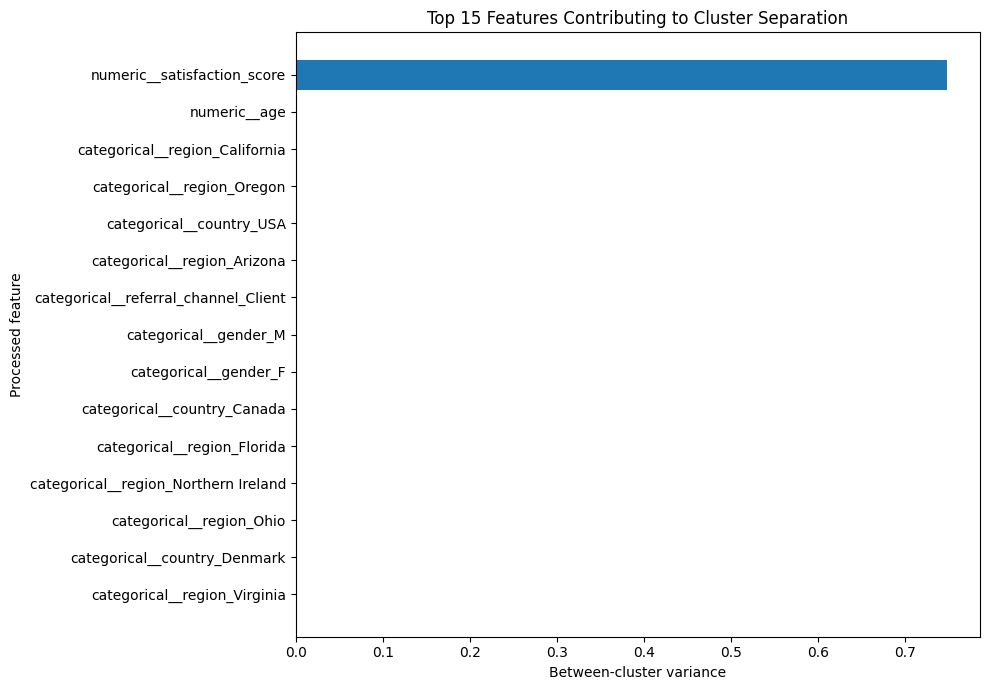

In [20]:
# Step 3.2: Visualize the top 15 features

top_features = feature_importance.head(15).sort_values(
    "Separation_Score",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Separation_Score"]
)

plt.xlabel("Between-cluster variance")
plt.ylabel("Processed feature")
plt.title("Top 15 Features Contributing to Cluster Separation")

plt.tight_layout()
plt.show()

CONTRIBUTION BY ORIGINAL CUSTOMER FEATURE


,Original_Feature,Total_Separation_Score,Contribution_Percent
8,satisfaction_score,0.75,99.88
1,age,0.00,0.05
7,region,0.00,0.04
3,country,0.00,0.01
4,gender,0.00,0.01
6,referral_channel,0.00,0.00
2,client_type,0.00,0.00
5,loan_applied,0.00,0.00
0,acquisition_purpose,0.00,0.00


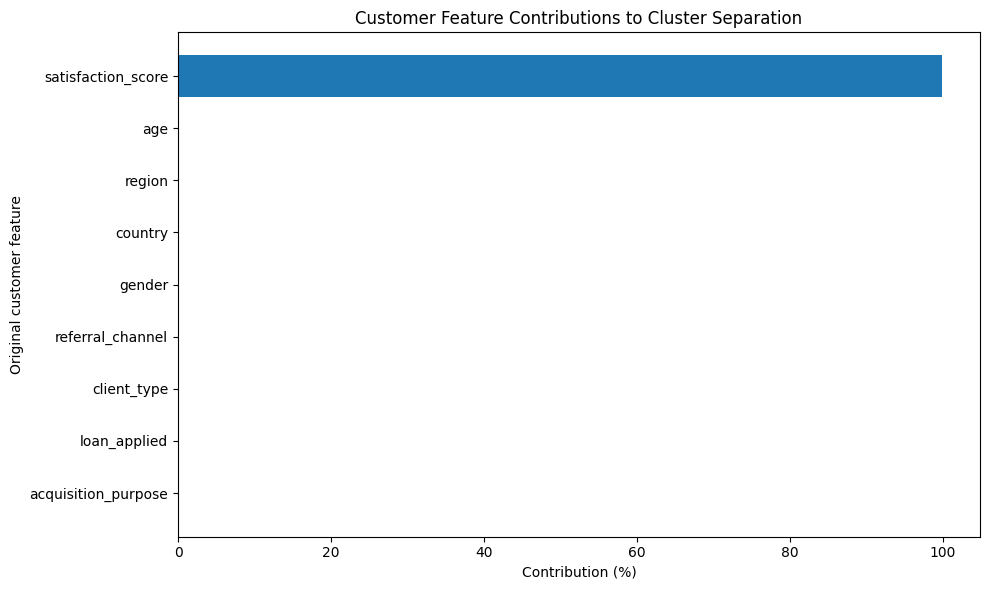

Saved: original_feature_contributions.csv


In [21]:
# Step 3.3: Group encoded columns by their original feature

categorical_fields = [
    "client_type",
    "gender",
    "country",
    "region",
    "acquisition_purpose",
    "loan_applied",
    "referral_channel"
]

def get_original_feature(column):
    # Numeric features
    if column.startswith("numeric__"):
        return column.replace("numeric__", "", 1)

    # Categorical features
    if column.startswith("categorical__"):
        name = column.replace("categorical__", "", 1)

        for field in categorical_fields:
            if name == field or name.startswith(field + "_"):
                return field

        return name

    return column

# Use all feature rows, not just the top 15
feature_importance["Original_Feature"] = (
    feature_importance["Feature"].apply(get_original_feature)
)

# Combine contributions belonging to the same original feature
original_feature_importance = (
    feature_importance
    .groupby("Original_Feature", as_index=False)
    .agg(
        Total_Separation_Score=("Separation_Score", "sum")
    )
    .sort_values("Total_Separation_Score", ascending=False)
)

# Calculate percentage of total between-cluster variance
total = original_feature_importance["Total_Separation_Score"].sum()

original_feature_importance["Contribution_Percent"] = (
    original_feature_importance["Total_Separation_Score"]
    / total * 100
)

print("CONTRIBUTION BY ORIGINAL CUSTOMER FEATURE")
display(original_feature_importance.round(2))

# Plot all original features
plot_data = original_feature_importance.sort_values(
    "Total_Separation_Score"
)

plt.figure(figsize=(10, 6))
plt.barh(
    plot_data["Original_Feature"],
    plot_data["Contribution_Percent"]
)
plt.xlabel("Contribution (%)")
plt.ylabel("Original customer feature")
plt.title("Customer Feature Contributions to Cluster Separation")
plt.tight_layout()
plt.show()

original_feature_importance.to_csv(
    "original_feature_contributions.csv",
    index=False
)

print("Saved: original_feature_contributions.csv")

In [23]:
# STEP 4.1: Compare existing customer clusters

# Combine original customer details with cluster labels
profile = clients.merge(
    clustered[["client_id", "cluster"]],
    on="client_id",
    how="inner",
    validate="one_to_one"
)

print("Number of customers in each cluster:")
print(profile["cluster"].value_counts().sort_index())

# Compare customer satisfaction and age
numeric_columns = [
    col for col in ["age", "satisfaction_score"]
    if col in profile.columns
]

print("\nAverage values by cluster:")
display(
    profile.groupby("cluster")[numeric_columns]
    .mean()
    .round(2)
)

# Compare buyer-related categories
categorical_columns = [
    "acquisition_purpose",
    "loan_applied",
    "client_type",
    "gender",
    "country",
    "region",
    "referral_channel"
]

for col in categorical_columns:
    if col in profile.columns:
        print(f"\n{col.upper()} — percentage within each cluster")

        percentages = pd.crosstab(
            profile["cluster"],
            profile[col],
            normalize="index"
        ) * 100

        display(percentages.round(1))

Number of customers in each cluster:
cluster
0     774
1    1226
Name: count, dtype: int64

Average values by cluster:


,satisfaction_score
cluster,
0,1.49
1,4.00



ACQUISITION_PURPOSE — percentage within each cluster


acquisition_purpose,Home,Investment
cluster,,
0,69.3,30.7
1,69.2,30.8



LOAN_APPLIED — percentage within each cluster


...

country,Australia,Belgium,Canada,Denmark,France,Germany,Mexico,Russia,UK,USA
cluster,,,,,,,,,,
0,2.1,2.5,3.7,1.2,2.5,2.5,1.7,1.9,4.4,77.6
1,1.9,2.0,4.6,0.5,2.8,3.0,2.2,1.7,5.0,76.4



REGION — percentage within each cluster


region,Alberta,Arizona,Baja California,Bavaria,Berlin,British Columbia,Brittany,Brussels,California,Capital Region,...,Texas,Utah,Victoria,Virginia,Wales,Wallonia,Washington,Western Australia,Wyoming,Zealand
cluster,,,,,,,,,,,,,,,,,,,,,
0,1.3,4.8,0.4,0.4,0.5,0.9,0.9,0.9,32.9,0.5,...,2.6,4.5,0.9,2.8,0.5,0.4,3.5,0.0,0.0,0.1
1,1.4,5.8,0.3,0.7,0.6,1.1,0.7,0.4,30.8,0.1,...,2.9,4.2,0.5,3.5,1.1,1.0,3.8,0.5,0.1,0.1



REFERRAL_CHANNEL — percentage within each cluster


referral_channel,Agency,Client,Website
cluster,,,
0,35.0,10.2,54.8
1,35.4,9.2,55.4


In [24]:
# STEP 5.1: Prepare customer features without satisfaction score

# Remove satisfaction score from the existing processed features
X_without_satisfaction = X.drop(
    columns=["numeric__satisfaction_score"],
    errors="ignore"
).copy()

print("Original feature count:", X.shape[1])
print("New feature count:", X_without_satisfaction.shape[1])
print(
    "Satisfaction feature removed:",
    "numeric__satisfaction_score" not in X_without_satisfaction.columns
)

display(X_without_satisfaction.head())

Original feature count: 80
New feature count: 79
Satisfaction feature removed: True


,categorical__client_type_Company,categorical__client_type_Individual,categorical__gender_F,categorical__gender_M,categorical__country_Australia,categorical__country_Belgium,categorical__country_Canada,categorical__country_Denmark,categorical__country_France,categorical__country_Germany,...,categorical__region_Wyoming,categorical__region_Zealand,categorical__acquisition_purpose_Home,categorical__acquisition_purpose_Investment,categorical__loan_applied_No,categorical__loan_applied_Yes,categorical__referral_channel_Agency,categorical__referral_channel_Client,categorical__referral_channel_Website,numeric__age
0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.109549
1,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.455585
2,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.628603
3,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.628603
4,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,-0.351832


Training K-Means with K=2...
Training K-Means with K=3...
Training K-Means with K=4...

MODEL COMPARISON:


,Number_of_Clusters,Silhouette_Score,Inertia,Smallest_Cluster,Largest_Cluster
0,2,0.1535,7187.2582,978,1022
1,3,0.1211,6630.5819,603,766
2,4,0.1199,6208.4971,389,580


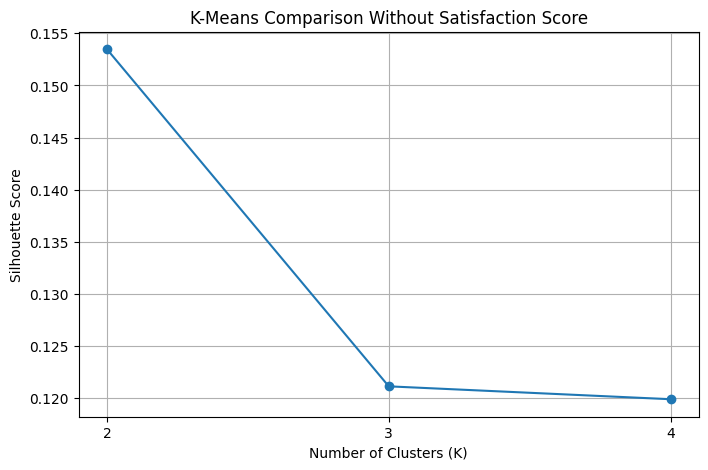

Saved: kmeans_without_satisfaction_comparison.csv


In [25]:
# STEP 5.2: Compare K-Means with 2, 3, and 4 clusters

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd
import matplotlib.pyplot as plt

results = []
trained_models = {}

for k in [2, 3, 4]:
    print(f"Training K-Means with K={k}...")

    model_k = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels_k = model_k.fit_predict(X_without_satisfaction)

    score = silhouette_score(
        X_without_satisfaction,
        labels_k
    )

    trained_models[k] = model_k

    results.append({
        "Number_of_Clusters": k,
        "Silhouette_Score": score,
        "Inertia": model_k.inertia_,
        "Smallest_Cluster": pd.Series(labels_k).value_counts().min(),
        "Largest_Cluster": pd.Series(labels_k).value_counts().max()
    })

results_df = pd.DataFrame(results)

print("\nMODEL COMPARISON:")
display(results_df.round(4))

# Visualize the scores
plt.figure(figsize=(8, 5))
plt.plot(
    results_df["Number_of_Clusters"],
    results_df["Silhouette_Score"],
    marker="o"
)

plt.xticks([2, 3, 4])
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("K-Means Comparison Without Satisfaction Score")
plt.grid(True)
plt.show()

results_df.to_csv(
    "kmeans_without_satisfaction_comparison.csv",
    index=False
)

print("Saved: kmeans_without_satisfaction_comparison.csv")

In [26]:
# STEP 5.3: Compare buyer profiles without satisfaction score

categorical_fields = [
    "acquisition_purpose",
    "loan_applied",
    "client_type",
    "country",
    "referral_channel"
]

for k in [2, 4]:

    print("\n" + "=" * 60)
    print(f"BUYER PROFILE ANALYSIS: K = {k}")
    print("=" * 60)

    # Use the models trained in Step 5.2
    labels_k = trained_models[k].predict(X_without_satisfaction)

    # Attach cluster labels to the original customer records
    temp = clients.copy()
    temp["cluster"] = labels_k

    print("\n1. Number of customers in each cluster")
    print(temp["cluster"].value_counts().sort_index())

    for field in categorical_fields:
        if field in temp.columns:
            print(f"\n2. {field.upper()} (%)")

            table = pd.crosstab(
                temp["cluster"],
                temp[field],
                normalize="index"
            ) * 100

            display(table.round(1))

    print("\n3. Average satisfaction score by cluster (for analysis only)")
    if "satisfaction_score" in temp.columns:
        display(
            temp.groupby("cluster")["satisfaction_score"]
            .mean()
            .round(2)
        )


BUYER PROFILE ANALYSIS: K = 2

1. Number of customers in each cluster
cluster
0     978
1    1022
Name: count, dtype: int64

2. ACQUISITION_PURPOSE (%)


acquisition_purpose,Home,Investment
cluster,,
0,66.0,34.0
1,72.4,27.6



2. LOAN_APPLIED (%)


loan_applied,No,Yes
cluster,,
0,60.5,39.5
1,65.8,34.2



2. CLIENT_TYPE (%)


...

country,Australia,Belgium,Canada,Denmark,France,Germany,Mexico,Russia,UK,USA
cluster,,,,,,,,,,
0,1.8,2.0,3.2,0.2,2.4,1.4,1.4,2.0,4.9,80.9
1,1.5,2.3,4.1,1.0,2.3,3.1,2.6,1.0,5.1,76.9
2,2.8,2.2,4.1,1.0,3.1,3.4,1.7,2.2,5.0,74.3
3,1.5,2.1,5.5,0.8,2.7,3.2,2.5,1.7,4.0,76.0



2. REFERRAL_CHANNEL (%)


referral_channel,Agency,Client,Website
cluster,,,
0,34.5,9.1,56.4
1,36.2,10.8,53.0
2,35.0,10.0,55.0
3,35.5,8.8,55.7



3. Average satisfaction score by cluster (for analysis only)


,satisfaction_score
cluster,
0,3.04
1,3.02
2,3.01
3,3.04


In [27]:
# STEP 5.4: Compare age and satisfaction across K=4 clusters

labels_4 = trained_models[4].predict(X_without_satisfaction)

age_profile = clients.copy()
age_profile["cluster"] = labels_4

# Calculate age using the same reference date as feature engineering
age_profile["date_of_birth"] = pd.to_datetime(
    age_profile["date_of_birth"], errors="coerce"
)

reference_date = pd.Timestamp("2025-01-01")

age_profile["age"] = (
    reference_date.year - age_profile["date_of_birth"].dt.year
    - (
        (age_profile["date_of_birth"].dt.month > reference_date.month)
        | (
            (age_profile["date_of_birth"].dt.month == reference_date.month)
            & (age_profile["date_of_birth"].dt.day > reference_date.day)
        )
    ).astype("Int64")
)

summary = age_profile.groupby("cluster").agg(
    customer_count=("client_id", "count"),
    average_age=("age", "mean"),
    median_age=("age", "median"),
    average_satisfaction=("satisfaction_score", "mean")
).round(2)

display(summary)

summary.to_csv("k4_age_profile_comparison.csv")
print("Saved: k4_age_profile_comparison.csv")

,customer_count,average_age,median_age,average_satisfaction
cluster,,,,
0,507,68.06,68.0,3.04
1,389,42.3,43.0,3.02
2,580,36.98,36.0,3.01
3,524,68.31,68.0,3.04


Saved: k4_age_profile_comparison.csv


In [28]:
# STEP 5.5: Create a complete four-cluster buyer profile

labels_4 = trained_models[4].predict(X_without_satisfaction)

buyer_profile = clients.copy()
buyer_profile["cluster"] = labels_4

# Summarize buyer characteristics
profile_summary = buyer_profile.groupby("cluster").agg(
    customers=("client_id", "count"),
    avg_age=("date_of_birth", "count"),
    avg_satisfaction=("satisfaction_score", "mean")
)

# Replace the temporary age count with actual age
dob = pd.to_datetime(buyer_profile["date_of_birth"], errors="coerce")
ref_date = pd.Timestamp("2025-01-01")

buyer_profile["age"] = (
    ref_date.year - dob.dt.year
    - (
        (dob.dt.month > ref_date.month)
        | (
            (dob.dt.month == ref_date.month)
            & (dob.dt.day > ref_date.day)
        )
    ).astype("Int64")
)

profile_summary["avg_age"] = (
    buyer_profile.groupby("cluster")["age"].mean()
)

# Add buyer-purpose and company-customer percentages
for column, category in [
    ("acquisition_purpose", "Investment"),
    ("client_type", "Company"),
    ("loan_applied", "Yes")
]:
    profile_summary[f"{category}_percent"] = (
        buyer_profile.groupby("cluster")[column]
        .apply(lambda s: s.eq(category).mean() * 100)
    )

profile_summary = profile_summary.drop(columns=["avg_age"]).join(
    buyer_profile.groupby("cluster")["age"].mean().rename("avg_age")
)

profile_summary = profile_summary[
    [
        "customers",
        "avg_age",
        "avg_satisfaction",
        "Investment_percent",
        "Company_percent",
        "Yes_percent"
    ]
].round(2)

display(profile_summary)

profile_summary.to_csv("final_buyer_profile_comparison.csv")
print("Saved: final_buyer_profile_comparison.csv")

,customers,avg_age,avg_satisfaction,Investment_percent,Company_percent,Yes_percent
cluster,,,,,,
0,507,68.06,3.04,22.68,2.76,37.48
1,389,42.3,3.02,100.00,8.48,41.13
2,580,36.98,3.01,0.00,7.24,36.03
3,524,68.31,3.04,21.18,2.67,33.78


Saved: final_buyer_profile_comparison.csv


In [29]:
# STEP 5.6.1: Weight categorical feature groups

import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Start with the 79 features without satisfaction score
X_weighted = X_without_satisfaction.copy()

# Original categorical fields
categorical_fields = [
    "client_type",
    "gender",
    "country",
    "region",
    "acquisition_purpose",
    "loan_applied",
    "referral_channel"
]

# Find the encoded columns belonging to each field
feature_groups = {}

for field in categorical_fields:
    prefix = f"categorical__{field}_"

    feature_groups[field] = [
        col for col in X_weighted.columns
        if col.startswith(prefix)
    ]

# Reduce the influence of fields with many encoded columns
for field, columns in feature_groups.items():
    if columns:
        X_weighted.loc[:, columns] = (
            X_weighted[columns] / np.sqrt(len(columns))
        )

print("Original feature count:", X.shape[1])
print("Features without satisfaction:", X_without_satisfaction.shape[1])
print("Weighted feature count:", X_weighted.shape[1])

print("\nCategorical columns per field:")
for field, columns in feature_groups.items():
    print(f"{field}: {len(columns)} columns")

print("\nMissing values:", X_weighted.isnull().sum().sum())
print("\nWeighted feature preparation completed.")

Original feature count: 80
Features without satisfaction: 79
Weighted feature count: 79

Categorical columns per field:
client_type: 2 columns
gender: 2 columns
country: 10 columns
region: 57 columns
acquisition_purpose: 2 columns
loan_applied: 2 columns
referral_channel: 3 columns

Missing values: 0

Weighted feature preparation completed.


Training weighted K-Means with K=2...
Training weighted K-Means with K=3...
Training weighted K-Means with K=4...

WEIGHTED CLUSTERING RESULTS


,K,Silhouette_Score,Inertia,Smallest_Cluster,Largest_Cluster
0,2,0.3012,2507.8543,969,1031
1,3,0.1877,2198.1743,634,728
2,4,0.1880,1998.2067,420,567


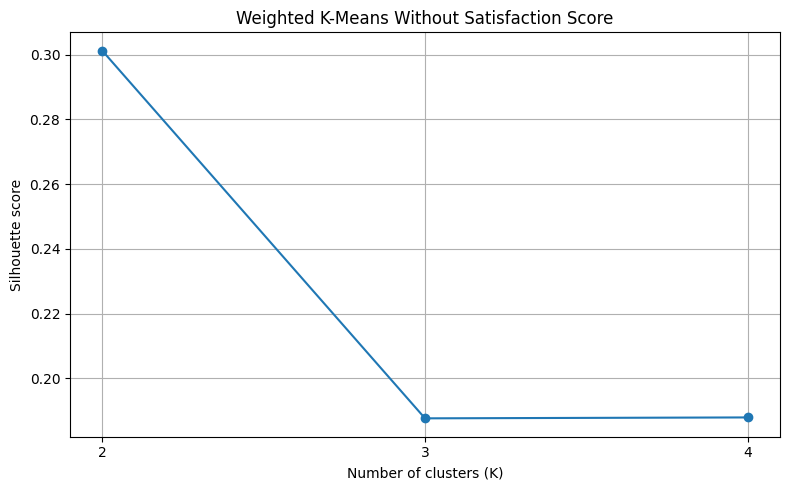

Saved: weighted_clustering_comparison.csv


In [30]:
# STEP 5.6.2: Train and compare weighted K-Means models

results_weighted = []
weighted_models = {}
weighted_labels = {}

for k in [2, 3, 4]:
    print(f"Training weighted K-Means with K={k}...")

    km = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels_k = km.fit_predict(X_weighted)

    score = silhouette_score(X_weighted, labels_k)

    weighted_models[k] = km
    weighted_labels[k] = labels_k

    cluster_sizes = pd.Series(labels_k).value_counts()

    results_weighted.append({
        "K": k,
        "Silhouette_Score": score,
        "Inertia": km.inertia_,
        "Smallest_Cluster": cluster_sizes.min(),
        "Largest_Cluster": cluster_sizes.max()
    })

weighted_results_df = pd.DataFrame(results_weighted)

print("\nWEIGHTED CLUSTERING RESULTS")
display(weighted_results_df.round(4))

# Plot silhouette scores
plt.figure(figsize=(8, 5))
plt.plot(
    weighted_results_df["K"],
    weighted_results_df["Silhouette_Score"],
    marker="o"
)
plt.xticks([2, 3, 4])
plt.xlabel("Number of clusters (K)")
plt.ylabel("Silhouette score")
plt.title("Weighted K-Means Without Satisfaction Score")
plt.grid(True)
plt.tight_layout()
plt.show()

weighted_results_df.to_csv(
    "weighted_clustering_comparison.csv",
    index=False
)

print("Saved: weighted_clustering_comparison.csv")

In [31]:
# STEP 5.6.3: Analyze improved K=2 buyer segments

# Use the weighted K=2 model created in Step 5.6.2
labels_2 = weighted_labels[2]

buyer_profile = clients.copy()
buyer_profile["cluster"] = labels_2

print("CUSTOMER COUNTS")
print(buyer_profile["cluster"].value_counts().sort_index())

# Compare numerical features
print("\nAVERAGE AGE AND SATISFACTION")
dob = pd.to_datetime(buyer_profile["date_of_birth"], errors="coerce")
reference_date = pd.Timestamp("2025-01-01")

buyer_profile["age"] = (
    reference_date.year - dob.dt.year
    - (
        (dob.dt.month > reference_date.month)
        | (
            (dob.dt.month == reference_date.month)
            & (dob.dt.day > reference_date.day)
        )
    ).astype("Int64")
)

display(
    buyer_profile.groupby("cluster").agg(
        customers=("client_id", "count"),
        average_age=("age", "mean"),
        average_satisfaction=("satisfaction_score", "mean")
    ).round(2)
)

# Compare the main buyer characteristics
fields = [
    "acquisition_purpose",
    "loan_applied",
    "client_type",
    "gender",
    "country",
    "referral_channel"
]

for field in fields:
    print(f"\n{field.upper()} — percentage in each cluster")

    table = pd.crosstab(
        buyer_profile["cluster"],
        buyer_profile[field],
        normalize="index"
    ) * 100

    display(table.round(1))

# Save the improved cluster assignments
buyer_profile[["client_id", "cluster"]].to_csv(
    "weighted_kmeans_k2_assignments.csv",
    index=False
)

print("Saved: weighted_kmeans_k2_assignments.csv")

CUSTOMER COUNTS
cluster
0     969
1    1031
Name: count, dtype: int64

AVERAGE AGE AND SATISFACTION


,customers,average_age,average_satisfaction
cluster,,,
0,969,38.8,3.02
1,1031,68.48,3.03



ACQUISITION_PURPOSE — percentage in each cluster


acquisition_purpose,Home,Investment
cluster,,
0,66.7,33.3
1,71.7,28.3



LOAN_APPLIED — percentage in each cluster


...


COUNTRY — percentage in each cluster


country,Australia,Belgium,Canada,Denmark,France,Germany,Mexico,Russia,UK,USA
cluster,,,,,,,,,,
0,2.3,2.2,4.2,0.9,2.8,3.2,2.0,1.8,5.0,75.7
1,1.6,2.1,4.3,0.6,2.5,2.4,2.0,1.8,4.6,78.0



REFERRAL_CHANNEL — percentage in each cluster


referral_channel,Agency,Client,Website
cluster,,,
0,35.0,10.5,54.5
1,35.5,8.7,55.8


Saved: weighted_kmeans_k2_assignments.csv


In [32]:
# Analyze the improved weighted K=2 clusters

buyer_profile = clients.copy()
buyer_profile["cluster"] = weighted_labels[2]

# Calculate age
dob = pd.to_datetime(buyer_profile["date_of_birth"], errors="coerce")
ref_date = pd.Timestamp("2025-01-01")

buyer_profile["age"] = (
    ref_date.year - dob.dt.year
    - (
        (dob.dt.month > ref_date.month)
        | (
            (dob.dt.month == ref_date.month)
            & (dob.dt.day > ref_date.day)
        )
    ).astype("Int64")
)

# Numerical summary
summary = buyer_profile.groupby("cluster").agg(
    customers=("client_id", "count"),
    average_age=("age", "mean"),
    average_satisfaction=("satisfaction_score", "mean")
).round(2)

display(summary)

# Categorical comparisons
for field in [
    "acquisition_purpose",
    "loan_applied",
    "client_type",
    "gender",
    "referral_channel"
]:
    print(f"\n{field.upper()} (%)")

    display(
        (
            pd.crosstab(
                buyer_profile["cluster"],
                buyer_profile[field],
                normalize="index"
            ) * 100
        ).round(1)
    )

# Save the complete customer profile data
buyer_profile.to_csv(
    "weighted_k2_buyer_profile.csv",
    index=False
)

print("\nSaved: weighted_k2_buyer_profile.csv")

,customers,average_age,average_satisfaction
cluster,,,
0,969,38.8,3.02
1,1031,68.48,3.03



ACQUISITION_PURPOSE (%)


acquisition_purpose,Home,Investment
cluster,,
0,66.7,33.3
1,71.7,28.3



LOAN_APPLIED (%)


loan_applied,No,Yes
cluster,,
0,61.0,39.0
1,65.3,34.7


...


GENDER (%)


gender,F,M
cluster,,
0,49.4,50.6
1,49.4,50.6



REFERRAL_CHANNEL (%)


referral_channel,Agency,Client,Website
cluster,,,
0,35.0,10.5,54.5
1,35.5,8.7,55.8



Saved: weighted_k2_buyer_profile.csv


In [33]:
import joblib
import json

# Save the improved K-Means model
joblib.dump(
    weighted_models[2],
    "weighted_kmeans_buyer_segmentation_model.joblib"
)

# Save the exact feature columns and configuration
configuration = {
    "n_clusters": 2,
    "random_state": 42,
    "features": list(X_weighted.columns),
    "excluded_features": ["numeric__satisfaction_score"],
    "categorical_weighting": {
        field: len(columns)
        for field, columns in feature_groups.items()
    }
}

with open("weighted_clustering_config.json", "w") as f:
    json.dump(configuration, f, indent=4)

print("Saved weighted_kmeans_buyer_segmentation_model.joblib")
print("Saved weighted_clustering_config.json")

Saved weighted_kmeans_buyer_segmentation_model.joblib
Saved weighted_clustering_config.json


In [34]:
# 5.7.1 — Test the saved model
import joblib
import numpy as np
from sklearn.metrics import adjusted_rand_score

# Load the saved improved model
saved_model = joblib.load(
    "weighted_kmeans_buyer_segmentation_model.joblib"
)

# Check feature count
print("Features in weighted dataset:", X_weighted.shape[1])
print("Features expected by model:", saved_model.n_features_in_)

assert X_weighted.shape[1] == saved_model.n_features_in_, (
    "Feature count mismatch!"
)

# Predict using the saved model
saved_predictions = saved_model.predict(X_weighted)

# Compare with the original K=2 weighted model predictions
original_predictions = weighted_labels[2]

ari = adjusted_rand_score(
    original_predictions,
    saved_predictions
)

print("\nAdjusted Rand Index:", round(ari, 6))
print("\nSaved model cluster counts:")
print(
    pd.Series(saved_predictions)
    .value_counts()
    .sort_index()
)

if ari == 1.0:
    print("\nPASS: Saved model reproduces the original clusters.")
else:
    print("\nCHECK: Predictions differ. Investigate the model and features.")

Features in weighted dataset: 79
Features expected by model: 79

Adjusted Rand Index: 1.0

Saved model cluster counts:
0     969
1    1031
Name: count, dtype: int64

PASS: Saved model reproduces the original clusters.


In [35]:
# STEP 5.8.1: Create reusable buyer prediction function

import numpy as np
import pandas as pd
import joblib
import json

# Load saved model and configuration
buyer_model = joblib.load(
    "weighted_kmeans_buyer_segmentation_model.joblib"
)

with open("weighted_clustering_config.json", "r") as f:
    buyer_config = json.load(f)

# Use the same weighted feature matrix structure as training
expected_features = buyer_config["features"]

assert list(X_weighted.columns) == expected_features, (
    "Feature names or order do not match the saved configuration."
)

# Define prediction function for already processed, weighted features
def predict_buyer_cluster(processed_customer):
    """
    Predict the cluster for one customer or multiple customers.

    Input must be preprocessed and weighted using the same
    transformations used during model training.
    """
    if isinstance(processed_customer, pd.Series):
        processed_customer = processed_customer.to_frame().T

    # Ensure feature order matches training
    processed_customer = processed_customer.reindex(
        columns=expected_features
    )

    if processed_customer.isnull().any().any():
        raise ValueError(
            "Input contains missing features or incorrect feature names."
        )

    predictions = buyer_model.predict(processed_customer)

    return predictions


# Test using one existing processed customer
test_customer = X_weighted.iloc[[0]]

test_prediction = predict_buyer_cluster(test_customer)

print("Test successful!")
print("Predicted buyer cluster:", int(test_prediction[0]))
print("Input feature count:", test_customer.shape[1])
print("Expected feature count:", buyer_model.n_features_in_)

Test successful!
Predicted buyer cluster: 1
Input feature count: 79
Expected feature count: 79


In [36]:
# Step 5.8.2: Verify prediction consistency

import numpy as np

sample_index = 0

# Predict the cluster for the selected customer
predicted_cluster = int(
    buyer_model.predict(X_weighted.iloc[[sample_index]])[0]
)

# Compare against the cluster label generated earlier
original_cluster = int(weighted_labels[2][sample_index])

print("Predicted cluster:", predicted_cluster)
print("Original cluster:", original_cluster)
print("Prediction matches:", predicted_cluster == original_cluster)

assert predicted_cluster == original_cluster, \
    "The prediction does not match the original cluster assignment."

print("\nStep 5.8.2 completed successfully!")

Predicted cluster: 1
Original cluster: 1
Prediction matches: True

Step 5.8.2 completed successfully!


In [37]:
# Step 5.8.3: Load and inspect the preprocessing pipeline

import joblib
import json

preprocessor = joblib.load("buyer_segmentation_preprocessor.joblib")

with open("weighted_clustering_config.json", "r") as f:
    buyer_config = json.load(f)

print("Preprocessor loaded successfully!")
print("Expected raw input columns:")

if hasattr(preprocessor, "feature_names_in_"):
    print(list(preprocessor.feature_names_in_))
else:
    print("Input columns are not recorded in feature_names_in_.")

print("\nExpected model features:", len(buyer_config["features"]))
print("Categorical weighting groups:")
print(buyer_config["categorical_weighting"])

Preprocessor loaded successfully!
Expected raw input columns:
['client_type', 'gender', 'country', 'region', 'acquisition_purpose', 'loan_applied', 'referral_channel', 'age', 'satisfaction_score']

Expected model features: 79
Categorical weighting groups:
{'client_type': 2, 'gender': 2, 'country': 10, 'region': 57, 'acquisition_purpose': 2, 'loan_applied': 2, 'referral_channel': 3}


In [38]:

# Step 5.8.4: Predict a cluster for a new customer

import numpy as np
import pandas as pd

def predict_new_buyer(customer_data):
    """
    Predict a buyer cluster from raw customer details.
    satisfaction_score is required by the preprocessor but
    excluded from the final clustering features.
    """

    # Convert input into a DataFrame
    if isinstance(customer_data, dict):
        customer_data = pd.DataFrame([customer_data])
    elif isinstance(customer_data, pd.Series):
        customer_data = customer_data.to_frame().T

    # Required columns in the exact expected order
    raw_columns = list(preprocessor.feature_names_in_)
    customer_data = customer_data.reindex(columns=raw_columns)

    if customer_data.isnull().any().any():
        raise ValueError(
            "Missing input values. Provide every required field."
        )

    # Apply the saved preprocessing pipeline
    transformed = preprocessor.transform(customer_data)

    # Handle sparse or dense output
    if hasattr(transformed, "toarray"):
        transformed = transformed.toarray()

    # Recover the exact transformed feature names
    feature_names = preprocessor.get_feature_names_out()

    processed_df = pd.DataFrame(
        transformed,
        columns=feature_names
    )

    # Remove satisfaction score because it was excluded during clustering
    processed_df = processed_df.drop(
        columns=["numeric__satisfaction_score"],
        errors="ignore"
    )

    # Apply the same categorical weighting used during training
    for feature, group_size in buyer_config[
        "categorical_weighting"
    ].items():

        prefix = f"categorical__{feature}_"

        group_columns = [
            col for col in processed_df.columns
            if col.startswith(prefix)
        ]

        if len(group_columns) != group_size:
            raise ValueError(
                f"Feature mismatch for {feature}: "
                f"expected {group_size} columns, "
                f"found {len(group_columns)}."
            )

        processed_df[group_columns] = (
            processed_df[group_columns] / np.sqrt(group_size)
        )

    # Match the saved model's exact feature order
    expected_features = buyer_config["features"]
    processed_df = processed_df.reindex(
        columns=expected_features
    )

    if processed_df.isnull().any().any():
        raise ValueError(
            "Missing processed features. Check category values "
            "against the training data."
        )

    # Predict the buyer segment
    prediction = int(buyer_model.predict(processed_df)[0])

    return prediction


In [39]:

# Step 5.8.4: Test using an existing customer record

clients = pd.read_csv("clients_cleaned.csv")

# Build the input expected by the preprocessor
sample_customer = clients.iloc[[0]].copy()

# Calculate age using the same reference date as training
sample_dob = pd.to_datetime(
    sample_customer["date_of_birth"],
    errors="coerce"
)

reference_date = pd.Timestamp("2025-01-01")

sample_customer["age"] = (
    reference_date.year
    - sample_dob.dt.year
    - (
        (sample_dob.dt.month > reference_date.month)
        | (
            (sample_dob.dt.month == reference_date.month)
            & (sample_dob.dt.day > reference_date.day)
        )
    ).astype("Int64")
)

# Add satisfaction_score if it is not present
if "satisfaction_score" not in sample_customer.columns:
    sample_customer["satisfaction_score"] = clients[
        "satisfaction_score"
    ].median()

# Keep only the preprocessor's required columns
sample_customer = sample_customer[
    list(preprocessor.feature_names_in_)
]

# Fill missing values to avoid invalid preprocessing input
for col in sample_customer.columns:
    if sample_customer[col].isnull().any():
        if col in buyer_config["categorical_weighting"]:
            sample_customer[col] = (
                clients[col].mode().iloc[0]
            )
        else:
            sample_customer[col] = clients[col].median()

# Predict the cluster
predicted_cluster = predict_new_buyer(sample_customer)

print("New-customer prediction test completed!")
print("Predicted buyer cluster:", predicted_cluster)
print("Processed model features:", len(buyer_config["features"]))


New-customer prediction test completed!
Predicted buyer cluster: 1
Processed model features: 79


In [40]:

# Step 5.8.5: Test predictions for 10 customers

test_customers = clients.head(10).copy()

# Calculate age using the same reference date as training
dob = pd.to_datetime(
    test_customers["date_of_birth"],
    errors="coerce"
)

reference_date = pd.Timestamp("2025-01-01")

test_customers["age"] = (
    reference_date.year
    - dob.dt.year
    - (
        (dob.dt.month > reference_date.month)
        | (
            (dob.dt.month == reference_date.month)
            & (dob.dt.day > reference_date.day)
        )
    ).astype("Int64")
)

# Supply satisfaction_score because the preprocessor requires it
if "satisfaction_score" not in test_customers.columns:
    test_customers["satisfaction_score"] = (
        clients["satisfaction_score"].median()
    )

# Keep the required columns and fill missing values
test_customers = test_customers[
    list(preprocessor.feature_names_in_)
].copy()

for col in test_customers.columns:
    if test_customers[col].isnull().any():
        if col in buyer_config["categorical_weighting"]:
            test_customers[col] = (
                test_customers[col].fillna(
                    clients[col].mode().iloc[0]
                )
            )
        else:
            test_customers[col] = (
                test_customers[col].fillna(
                    clients[col].median()
                )
            )

# Predict each customer
predictions = [
    predict_new_buyer(test_customers.iloc[[i]])
    for i in range(len(test_customers))
]

results = pd.DataFrame({
    "Customer_Number": range(1, len(predictions) + 1),
    "Predicted_Cluster": predictions
})

print(results.to_string(index=False))
print("\nTotal customers tested:", len(results))
print("Prediction counts:")
print(results["Predicted_Cluster"].value_counts().sort_index())


 Customer_Number  Predicted_Cluster
               1                  1
               2                  1
               3                  1
               4                  1
               5                  0
               6                  1
               7                  1
               8                  1
               9                  0
              10                  1

Total customers tested: 10
Prediction counts:
Predicted_Cluster
0    2
1    8
Name: count, dtype: int64


In [45]:
import os

for filename in os.listdir("/content"):
    if filename.endswith(".csv") and (
        "weighted" in filename.lower()
        or "cluster" in filename.lower()
        or "buyer" in filename.lower()
    ):
        print(filename)

kmeans_cluster_evaluation.csv
weighted_clustering_comparison.csv
weighted_k2_buyer_profile.csv
kmeans_buyer_segments.csv
client_ids_for_clustering.csv
clustering_validation_summary.csv
final_buyer_profile_comparison.csv
weighted_kmeans_k2_assignments.csv


In [46]:

# Step 5.9: Load the correct K-Means cluster assignments

import pandas as pd

assignments = pd.read_csv("weighted_kmeans_k2_assignments.csv")

print("Assignments loaded successfully!")
print("Dataset shape:", assignments.shape)

print("\nColumn names:")
print(assignments.columns.tolist())

print("\nFirst 5 rows:")
display(assignments.head())

print("\nCluster distribution:")
print(assignments.iloc[:, -1].value_counts().sort_index())


Assignments loaded successfully!
Dataset shape: (2000, 2)

Column names:
['client_id', 'cluster']

First 5 rows:


,client_id,cluster
0,C0001,1
1,C0002,1
2,C0003,1
3,C0004,1
4,C0005,0



Cluster distribution:
cluster
0     969
1    1031
Name: count, dtype: int64


In [47]:

# Step 5.9.2: Merge customer details with cluster assignments

import pandas as pd

# Load customer data
clients = pd.read_csv("clients_cleaned.csv")

# Merge using customer ID
clustered_clients = clients.merge(
    assignments[["client_id", "cluster"]],
    on="client_id",
    how="inner",
    validate="one_to_one"
)

# Calculate age using the same reference date as model training
dob = pd.to_datetime(
    clustered_clients["date_of_birth"],
    errors="coerce"
)

reference_date = pd.Timestamp("2025-01-01")

clustered_clients["age"] = (
    reference_date.year
    - dob.dt.year
    - (
        (dob.dt.month > reference_date.month)
        | (
            (dob.dt.month == reference_date.month)
            & (dob.dt.day > reference_date.day)
        )
    ).astype("Int64")
)

print("Merge completed successfully!")
print("Merged dataset shape:", clustered_clients.shape)
print("Unique customers:", clustered_clients["client_id"].nunique())

# Generate numerical summaries
profile_numeric = clustered_clients.groupby("cluster").agg(
    customer_count=("client_id", "count"),
    average_age=("age", "mean"),
    median_age=("age", "median"),
    average_satisfaction=("satisfaction_score", "mean")
).round(2)

print("\nNumerical buyer profiles:")
display(profile_numeric)

# Calculate percentages for key categorical features
for col in [
    "acquisition_purpose",
    "client_type",
    "loan_applied",
    "gender"
]:
    print(f"\n{col} distribution by cluster (%):")
    display(
        pd.crosstab(
            clustered_clients["cluster"],
            clustered_clients[col],
            normalize="index"
        ).mul(100).round(2)
    )


Merge completed successfully!
Merged dataset shape: (2000, 14)
Unique customers: 2000

Numerical buyer profiles:


,customer_count,average_age,median_age,average_satisfaction
cluster,,,,
0,969,38.8,39.0,3.02
1,1031,68.48,68.0,3.03



acquisition_purpose distribution by cluster (%):


acquisition_purpose,Home,Investment
cluster,,
0,66.67,33.33
1,71.68,28.32



client_type distribution by cluster (%):


client_type,Company,Individual
cluster,,
0,7.43,92.57
1,3.01,96.99



loan_applied distribution by cluster (%):


loan_applied,No,Yes
cluster,,
0,60.99,39.01
1,65.28,34.72



gender distribution by cluster (%):


gender,F,M
cluster,,
0,49.43,50.57
1,49.37,50.63


In [48]:

# Step 5.9.3: Generate and save the final buyer profiles

import pandas as pd

profile_rows = []

for cluster_id, group in clustered_clients.groupby("cluster"):
    profile_rows.append({
        "cluster": int(cluster_id),
        "customer_count": len(group),
        "average_age": round(group["age"].mean(), 2),
        "median_age": round(group["age"].median(), 2),
        "average_satisfaction": round(
            group["satisfaction_score"].mean(), 2
        ),
        "home_purpose_pct": round(
            group["acquisition_purpose"].eq("Home").mean() * 100, 2
        ),
        "investment_purpose_pct": round(
            group["acquisition_purpose"].eq("Investment").mean() * 100, 2
        ),
        "individual_pct": round(
            group["client_type"].eq("Individual").mean() * 100, 2
        ),
        "company_pct": round(
            group["client_type"].eq("Company").mean() * 100, 2
        ),
        "loan_applicant_pct": round(
            group["loan_applied"].eq("Yes").mean() * 100, 2
        ),
        "female_pct": round(
            group["gender"].eq("F").mean() * 100, 2
        ),
        "male_pct": round(
            group["gender"].eq("M").mean() * 100, 2
        )
    })

final_profiles = pd.DataFrame(profile_rows)

final_profiles.to_csv(
    "final_buyer_cluster_profiles.csv",
    index=False
)

display(final_profiles)

print("Saved: final_buyer_cluster_profiles.csv")


,cluster,customer_count,average_age,median_age,average_satisfaction,home_purpose_pct,investment_purpose_pct,individual_pct,company_pct,loan_applicant_pct,female_pct,male_pct
0,0,969,38.80,39.0,3.02,66.67,33.33,92.57,7.43,39.01,49.43,50.57
1,1,1031,68.48,68.0,3.03,71.68,28.32,96.99,3.01,34.72,49.37,50.63


Saved: final_buyer_cluster_profiles.csv


In [50]:

# Step 6.1: Verify dashboard files

import os

required_files = [
    "clients_cleaned.csv",
    "properties_cleaned.csv",
    "final_buyer_cluster_profiles.csv",
    "weighted_kmeans_buyer_segmentation_model.joblib",
    "weighted_clustering_config.json",
    "buyer_segmentation_preprocessor.joblib",
    "weighted_kmeans_k2_assignments.csv"
]

print("STEP 6.1 — DASHBOARD FILE CHECK")
print("-" * 45)

missing_files = []

for filename in required_files:
    if os.path.isfile(filename):
        print(f"[FOUND]   {filename}")
    else:
        print(f"[MISSING] {filename}")
        missing_files.append(filename)

print("-" * 45)

if not missing_files:
    print("SUCCESS: All required files are available.")
else:
    print(f"Missing files: {len(missing_files)}")
    print("Upload or regenerate the missing files before continuing.")


STEP 6.1 — DASHBOARD FILE CHECK
---------------------------------------------
[FOUND]   clients_cleaned.csv
[FOUND]   properties_cleaned.csv
[FOUND]   final_buyer_cluster_profiles.csv
[FOUND]   weighted_kmeans_buyer_segmentation_model.joblib
[FOUND]   weighted_clustering_config.json
[FOUND]   buyer_segmentation_preprocessor.joblib
[FOUND]   weighted_kmeans_k2_assignments.csv
---------------------------------------------
SUCCESS: All required files are available.


In [51]:

# Step 6.2: Install dashboard dependencies

%pip install -q streamlit plotly joblib scikit-learn


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.3/10.3 MB 59.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 57.3 MB/s eta 0:00:00


In [52]:

# Verify dashboard dependencies

import streamlit as st
import plotly.express as px
import pandas as pd
import joblib
import sklearn

print("Streamlit version:", st.__version__)
print("Plotly version:", px.__version__ if hasattr(px, "__version__") else "Installed")
print("Pandas version:", pd.__version__)
print("Scikit-learn version:", sklearn.__version__)
print("Joblib version:", joblib.__version__)

print("\nStep 6.2 completed successfully!")


Streamlit version: 1.65.0
Plotly version: Installed
Pandas version: 2.2.3
Scikit-learn version: 1.6.1
Joblib version: 1.6.0

Step 6.2 completed successfully!


In [53]:

# Step 6.3: Create the Streamlit dashboard application

%%writefile app.py

import json
import joblib
import numpy as np
import pandas as pd
import streamlit as st
import plotly.express as px

from pathlib import Path

# --------------------------------------------------
# 1. PAGE CONFIGURATION
# --------------------------------------------------

st.set_page_config(
    page_title="Real Estate Buyer Intelligence",
    page_icon="🏡",
    layout="wide"
)

st.title("🏡 Real Estate Buyer Intelligence")
st.caption(
    "Machine Learning-Based Buyer Segmentation "
    "and Investment Profiling"
)

# --------------------------------------------------
# 2. FILE CONFIGURATION
# --------------------------------------------------

BASE_DIR = Path(__file__).resolve().parent

@st.cache_data
def load_csv(filename):
    return pd.read_csv(BASE_DIR / filename)

@st.cache_resource
def load_model(filename):
    return joblib.load(BASE_DIR / filename)

@st.cache_data
def load_config(filename):
    with open(BASE_DIR / filename, "r") as file:
        return json.load(file)

# --------------------------------------------------
# 3. LOAD PROJECT DATA
# --------------------------------------------------

try:
    clients = load_csv("clients_cleaned.csv")
    properties = load_csv("properties_cleaned.csv")
    assignments = load_csv("weighted_kmeans_k2_assignments.csv")
    profiles = load_csv("final_buyer_cluster_profiles.csv")

    model = load_model(
        "weighted_kmeans_buyer_segmentation_model.joblib"
    )
    preprocessor = load_model(
        "buyer_segmentation_preprocessor.joblib"
    )
    config = load_config("weighted_clustering_config.json")

except Exception as error:
    st.error(f"Unable to load project files: {error}")
    st.stop()

# --------------------------------------------------
# 4. MERGE CUSTOMER ASSIGNMENTS
# --------------------------------------------------

data = clients.merge(
    assignments[["client_id", "cluster"]],
    on="client_id",
    how="left",
    validate="one_to_one"
)

data["cluster"] = data["cluster"].astype("Int64")

# Calculate age using the same reference date as training
dob = pd.to_datetime(data["date_of_birth"], errors="coerce")

data["age"] = (
    2025
    - dob.dt.year
    - (
        (dob.dt.month > 1)
        | (
            (dob.dt.month == 1)
            & (dob.dt.day > 1)
        )
    ).astype("Int64")
)

# --------------------------------------------------
# 5. SIDEBAR NAVIGATION
# --------------------------------------------------

st.sidebar.title("Navigation")

page = st.sidebar.radio(
    "Select a page",
    [
        "Overview",
        "Buyer Analytics",
        "Customer Explorer",
        "Model Information"
    ]
)

# --------------------------------------------------
# 6. OVERVIEW
# --------------------------------------------------

if page == "Overview":

    st.subheader("Market Intelligence Overview")

    col1, col2, col3, col4 = st.columns(4)

    col1.metric("Total Customers", f"{len(data):,}")
    col2.metric(
        "Cluster 0 Customers",
        f"{(data['cluster'] == 0).sum():,}"
    )
    col3.metric(
        "Cluster 1 Customers",
        f"{(data['cluster'] == 1).sum():,}"
    )
    col4.metric("Total Properties", f"{len(properties):,}")

    st.divider()

    left, right = st.columns(2)

    with left:
        cluster_counts = (
            data["cluster"]
            .value_counts()
            .sort_index()
            .rename_axis("Cluster")
            .reset_index(name="Customers")
        )

        fig = px.pie(
            cluster_counts,
            names="Cluster",
            values="Customers",
            title="Buyer Cluster Distribution",
            hole=0.45
        )
        st.plotly_chart(fig, use_container_width=True)

    with right:
        if "acquisition_purpose" in data.columns:
            purpose_counts = (
                data["acquisition_purpose"]
                .value_counts()
                .rename_axis("Purpose")
                .reset_index(name="Customers")
            )

            fig = px.bar(
                purpose_counts,
                x="Purpose",
                y="Customers",
                title="Customer Acquisition Purpose",
                text="Customers"
            )
            st.plotly_chart(fig, use_container_width=True)

    st.subheader("Buyer Cluster Profiles")
    st.dataframe(profiles, use_container_width=True)

# --------------------------------------------------
# 7. BUYER ANALYTICS
# --------------------------------------------------

elif page == "Buyer Analytics":

    st.subheader("Buyer Profile Analysis")

    selected_cluster = st.selectbox(
        "Select cluster",
        sorted(data["cluster"].dropna().unique().tolist())
    )

    subset = data[data["cluster"] == selected_cluster]

    col1, col2, col3 = st.columns(3)

    col1.metric("Customers", len(subset))
    col2.metric(
        "Average Age",
        f"{subset['age'].mean():.1f} years"
    )
    col3.metric(
        "Average Satisfaction",
        f"{subset['satisfaction_score'].mean():.2f}"
    )

    if "acquisition_purpose" in subset.columns:
        fig = px.histogram(
            subset,
            x="acquisition_purpose",
            title="Acquisition Purpose",
            text_auto=True
        )
        st.plotly_chart(fig, use_container_width=True)

    if "loan_applied" in subset.columns:
        loan_data = (
            subset["loan_applied"]
            .value_counts()
            .rename_axis("Loan Applied")
            .reset_index(name="Customers")
        )

        fig = px.bar(
            loan_data,
            x="Loan Applied",
            y="Customers",
            title="Loan Application Distribution",
            text="Customers"
        )
        st.plotly_chart(fig, use_container_width=True)

    st.caption(
        "Cluster numbers are unsupervised group labels, "
        "not investment-quality scores."
    )

# --------------------------------------------------
# 8. CUSTOMER EXPLORER
# --------------------------------------------------

elif page == "Customer Explorer":

    st.subheader("Explore Segmented Customers")

    cluster_filter = st.selectbox(
        "Filter by cluster",
        ["All"] + sorted(
            data["cluster"].dropna().unique().tolist()
        )
    )

    filtered = data.copy()

    if cluster_filter != "All":
        filtered = filtered[
            filtered["cluster"] == cluster_filter
        ]

    search_id = st.text_input("Search customer ID")

    if search_id:
        filtered = filtered[
            filtered["client_id"]
            .astype(str)
            .str.contains(search_id, case=False, na=False)
        ]

    st.write(f"Matching customers: {len(filtered):,}")

    display_columns = [
        column for column in [
            "client_id",
            "cluster",
            "age",
            "client_type",
            "gender",
            "country",
            "region",
            "acquisition_purpose",
            "loan_applied",
            "satisfaction_score"
        ]
        if column in filtered.columns
    ]

    st.dataframe(
        filtered[display_columns],
        use_container_width=True,
        hide_index=True
    )

    csv_data = filtered.to_csv(index=False).encode("utf-8")

    st.download_button(
        "Download Customer Results",
        data=csv_data,
        file_name="buyer_segmentation_results.csv",
        mime="text/csv"
    )

# --------------------------------------------------
# 9. MODEL INFORMATION
# --------------------------------------------------

elif page == "Model Information":

    st.subheader("Model Information")

    st.write("Algorithm: Weighted K-Means Clustering")
    st.write("Number of clusters:", config["n_clusters"])
    st.write("Random state:", config["random_state"])
    st.write("Expected model features:", len(config["features"]))

    st.write("Excluded features:", config["excluded_features"])

    st.info(
        "The model groups customers by feature similarity. "
        "Cluster assignments do not establish investment returns, "
        "creditworthiness, or future property performance."
    )

    st.subheader("Saved Cluster Profiles")
    st.dataframe(profiles, use_container_width=True)

st.sidebar.divider()
st.sidebar.caption("Buyer Segmentation Project")


Writing app.py


In [54]:

# Verify that app.py was created

from pathlib import Path

app_path = Path("/content/app.py")

print("Dashboard file exists:", app_path.exists())

if app_path.exists():
    print("Dashboard file size:", app_path.stat().st_size, "bytes")
    print("Dashboard file:", app_path)


Dashboard file exists: True
Dashboard file size: 8291 bytes
Dashboard file: /content/app.py


In [55]:

# Step 6.4: Validate the Streamlit application syntax

import ast
from pathlib import Path

app_path = Path("/content/app.py")
source_code = app_path.read_text(encoding="utf-8")

try:
    ast.parse(source_code)
    print("SUCCESS: Python syntax is valid!")
    print("File:", app_path)
    print("Lines of code:", len(source_code.splitlines()))
except SyntaxError as error:
    print("SYNTAX ERROR")
    print("Line:", error.lineno)
    print("Details:", error.msg)


SUCCESS: Python syntax is valid!
File: /content/app.py
Lines of code: 323


In [ ]:
# Step 6.5 — Launch Streamlit in Google Colab

In [56]:

%pip install -q pyngrok


In [58]:

from pyngrok import ngrok
import getpass

NGROK_TOKEN = getpass.getpass("Enter your ngrok authentication token: ")

ngrok.set_auth_token(NGROK_TOKEN)

print("ngrok authentication configured.")


Enter your ngrok authentication token: ··········
ngrok authentication configured.


In [59]:

import subprocess
import time
import requests
from pyngrok import ngrok

# Start Streamlit
process = subprocess.Popen(
    [
        "streamlit", "run", "/content/app.py",
        "--server.port", "8501",
        "--server.address", "0.0.0.0",
        "--server.headless", "true"
    ],
    stdout=open("/content/streamlit.log", "w"),
    stderr=subprocess.STDOUT
)

# Wait for Streamlit to start
for attempt in range(30):
    if process.poll() is not None:
        print("Streamlit exited. Check /content/streamlit.log")
        break

    try:
        response = requests.get(
            "http://127.0.0.1:8501/_stcore/health",
            timeout=2
        )
        if response.status_code == 200:
            print("Streamlit started successfully!")
            break
    except requests.RequestException:
        pass

    time.sleep(2)

# Create public tunnel
if process.poll() is None:
    public_url = ngrok.connect(8501, "http").public_url
    print("Open your dashboard here:")
    print(public_url)
else:
    print("Review the Streamlit log before creating the tunnel.")


Streamlit started successfully!
Open your dashboard here:
https://embody-serrated-crisply.ngrok-free.dev


In [60]:
# Step 6.6 — Add the customer prediction form

# Find where to insert the new prediction page

from pathlib import Path

source = Path("/content/app.py").read_text(encoding="utf-8")

search_text = '        "Customer Explorer",'

if search_text in source:
    print("Navigation location found.")
    print("We can safely add the Customer Prediction page.")
else:
    print("Navigation text not found. Inspect app.py before editing.")

print("\nCurrent navigation section:")
start = source.find('page = st.sidebar.radio')
print(source[start:start + 250])


Navigation location found.
We can safely add the Customer Prediction page.

Current navigation section:
page = st.sidebar.radio(
    "Select a page",
    [
        "Overview",
        "Buyer Analytics",
        "Customer Explorer",
        "Model Information"
    ]
)

# --------------------------------------------------
# 6. OVERVIEW
# ----------------


In [61]:

# Step 6.6: Add a new-customer prediction page

from pathlib import Path

app_path = Path("/content/app.py")
source = app_path.read_text(encoding="utf-8")

# Add the new page to the sidebar navigation
old_navigation = '''        "Buyer Analytics",
        "Customer Explorer",
        "Model Information"'''

new_navigation = '''        "Buyer Analytics",
        "Customer Explorer",
        "Customer Prediction",
        "Model Information"'''

if old_navigation in source:
    source = source.replace(old_navigation, new_navigation, 1)
elif '"Customer Prediction"' in source:
    print("Prediction page already exists in navigation.")
else:
    raise ValueError("Could not locate the navigation section.")

# Add the prediction page before Model Information
marker = 'elif page == "Model Information":'

prediction_code = r'''
elif page == "Customer Prediction":

    st.subheader("Predict a New Buyer's Segment")
    st.write(
        "Enter customer details to assign the buyer to one "
        "of the clusters identified by the trained K-Means model."
    )

    with st.form("buyer_prediction_form"):

        col1, col2 = st.columns(2)

        with col1:
            client_type = st.selectbox(
                "Client type",
                ["Individual", "Company"]
            )
            gender = st.selectbox("Gender", ["F", "M"])
            country = st.selectbox(
                "Country",
                sorted(clients["country"].dropna().unique().tolist())
            )
            region = st.selectbox(
                "Region",
                sorted(clients["region"].dropna().unique().tolist())
            )

        with col2:
            acquisition_purpose = st.selectbox(
                "Acquisition purpose",
                ["Home", "Investment"]
            )
            loan_applied = st.selectbox(
                "Loan applied",
                ["Yes", "No"]
            )
            referral_channel = st.selectbox(
                "Referral channel",
                sorted(
                    clients["referral_channel"]
                    .dropna()
                    .unique()
                    .tolist()
                )
            )
            age = st.number_input(
                "Age",
                min_value=18,
                max_value=100,
                value=40,
                step=1
            )

        submitted = st.form_submit_button(
            "Predict Buyer Cluster",
            type="primary",
            use_container_width=True
        )

    if submitted:

        try:
            raw_input = pd.DataFrame([{
                "client_type": client_type,
                "gender": gender,
                "country": country,
                "region": region,
                "acquisition_purpose": acquisition_purpose,
                "loan_applied": loan_applied,
                "referral_channel": referral_channel,
                "age": age,
                # The model excludes satisfaction from clustering.
                # This neutral value is only supplied because the
                # saved preprocessor requires the column.
                "satisfaction_score": float(
                    clients["satisfaction_score"].median()
                )
            }])

            transformed = preprocessor.transform(raw_input)

            if hasattr(transformed, "toarray"):
                transformed = transformed.toarray()

            feature_names = preprocessor.get_feature_names_out()

            processed = pd.DataFrame(
                transformed,
                columns=feature_names
            )

            processed = processed.drop(
                columns=["numeric__satisfaction_score"],
                errors="ignore"
            )

            for feature, group_size in (
                config["categorical_weighting"].items()
            ):
                prefix = f"categorical__{feature}_"
                group_columns = [
                    col for col in processed.columns
                    if col.startswith(prefix)
                ]

                if len(group_columns) != group_size:
                    raise ValueError(
                        f"Feature mismatch for {feature}. "
                        "A selected category may not match the "
                        "training configuration."
                    )

                processed[group_columns] = (
                    processed[group_columns] / np.sqrt(group_size)
                )

            processed = processed.reindex(
                columns=config["features"]
            )

            if processed.isnull().any().any():
                raise ValueError(
                    "Processed features contain missing values."
                )

            predicted_cluster = int(
                model.predict(processed)[0]
            )

            st.success(
                f"Predicted buyer cluster: {predicted_cluster}"
            )

            if predicted_cluster == 0:
                st.info(
                    "This buyer belongs to Cluster 0. "
                    "In the current dataset, this group has an "
                    "average age of about 38.8 years."
                )
            else:
                st.info(
                    "This buyer belongs to Cluster 1. "
                    "In the current dataset, this group has an "
                    "average age of about 68.5 years."
                )

            st.caption(
                "This is a similarity-based segment, not a prediction "
                "of property returns, investment success, or "
                "creditworthiness. New categories not seen during "
                "training may be ignored by the encoder."
            )

        except Exception as error:
            st.error(f"Prediction failed: {error}")

'''

if marker in source:
    if 'elif page == "Customer Prediction":' not in source:
        source = source.replace(marker, prediction_code + marker, 1)
else:
    raise ValueError("Could not locate the Model Information page.")

app_path.write_text(source, encoding="utf-8")

print("Customer Prediction page added successfully!")
print("Updated file:", app_path)
print("File size:", app_path.stat().st_size, "bytes")


Customer Prediction page added successfully!
Updated file: /content/app.py
File size: 13338 bytes


In [62]:

import ast
from pathlib import Path

source = Path("/content/app.py").read_text(encoding="utf-8")
ast.parse(source)

print("Python syntax: VALID")
print("Prediction page added:", 'page == "Customer Prediction"' in source)
print("Navigation updated:", '"Customer Prediction"' in source)
print("Dashboard is ready for relaunch.")


Python syntax: VALID
Prediction page added: True
Navigation updated: True
Dashboard is ready for relaunch.


In [63]:

# Step 6.7: Restart Streamlit with the updated app.py

import subprocess
import time
import requests
import os
from pathlib import Path

# Stop the previous Streamlit process if it is still running
if "process" in globals() and process.poll() is None:
    process.terminate()
    try:
        process.wait(timeout=10)
    except subprocess.TimeoutExpired:
        process.kill()
        process.wait()

# Start the updated dashboard
log_file = open("/content/streamlit.log", "w")

process = subprocess.Popen(
    [
        "streamlit", "run", "/content/app.py",
        "--server.port", "8501",
        "--server.address", "0.0.0.0",
        "--server.headless", "true"
    ],
    stdout=log_file,
    stderr=subprocess.STDOUT
)

# Wait for the server to become healthy
healthy = False

for attempt in range(30):
    if process.poll() is not None:
        print("Streamlit stopped unexpectedly.")
        break

    try:
        response = requests.get(
            "http://127.0.0.1:8501/_stcore/health",
            timeout=2
        )

        if response.status_code == 200:
            healthy = True
            break
    except requests.RequestException:
        pass

    time.sleep(2)

if healthy:
    print("Updated Streamlit dashboard is running!")
    print("Health check:", response.status_code)
    print("Port: 8501")
else:
    print("Dashboard did not start successfully.")
    print(Path("/content/streamlit.log").read_text()[-5000:])


Updated Streamlit dashboard is running!
Health check: 200
Port: 8501


In [64]:

# Step 6.8: Check the Streamlit server and ngrok tunnel

import requests
from pyngrok import ngrok

# Check the local Streamlit server
response = requests.get(
    "http://127.0.0.1:8501/_stcore/health",
    timeout=5
)

print("Local Streamlit status:", response.status_code)

# List existing ngrok tunnels
tunnels = ngrok.get_tunnels()

print("\nActive ngrok tunnels:")

for tunnel in tunnels:
    print("Public URL:", tunnel.public_url)
    print("Local address:", tunnel.config.get("addr", "Unknown"))

if not tunnels:
    print("\nNo active tunnel found.")
    print("Creating a new public tunnel...")

    tunnel = ngrok.connect(
        addr="http://127.0.0.1:8501",
        proto="http"
    )

    print("New dashboard URL:", tunnel.public_url)


Local Streamlit status: 200

Active ngrok tunnels:
Public URL: https://embody-serrated-crisply.ngrok-free.dev
Local address: http://localhost:8501


In [65]:

# Step 7.1: Final dataset validation

import pandas as pd

clients = pd.read_csv("clients_cleaned.csv")
assignments = pd.read_csv("weighted_kmeans_k2_assignments.csv")

print("STEP 7.1 — FINAL DATA VALIDATION")
print("-" * 45)

print("Customer records:", len(clients))
print("Unique customer IDs:", clients["client_id"].nunique())
print("Assignment records:", len(assignments))
print("Unique assigned customer IDs:", assignments["client_id"].nunique())

print("\nDuplicate customer IDs in clients:",
      clients["client_id"].duplicated().sum())

print("Duplicate customer IDs in assignments:",
      assignments["client_id"].duplicated().sum())

print("Missing cluster assignments:",
      assignments["cluster"].isna().sum())

print("\nCluster distribution:")
print(assignments["cluster"].value_counts().sort_index())

# Validate that both files contain exactly the same customer IDs
same_customer_ids = (
    set(clients["client_id"]) == set(assignments["client_id"])
)

print("\nCustomer IDs match:", same_customer_ids)

validation_passed = (
    len(clients) == 2000
    and len(assignments) == 2000
    and clients["client_id"].is_unique
    and assignments["client_id"].is_unique
    and assignments["cluster"].notna().all()
    and same_customer_ids
    and set(assignments["cluster"].unique()) == {0, 1}
)

print("\nFINAL VALIDATION:", "PASSED" if validation_passed else "FAILED")


STEP 7.1 — FINAL DATA VALIDATION
---------------------------------------------
Customer records: 2000
Unique customer IDs: 2000
Assignment records: 2000
Unique assigned customer IDs: 2000

Duplicate customer IDs in clients: 0
Duplicate customer IDs in assignments: 0
Missing cluster assignments: 0

Cluster distribution:
cluster
0     969
1    1031
Name: count, dtype: int64

Customer IDs match: True

FINAL VALIDATION: PASSED


In [67]:
# Step 7.2: Verify saved model prediction consistency

import joblib
import json
import numpy as np
import pandas as pd

# Load the saved model and configuration
model = joblib.load("weighted_kmeans_buyer_segmentation_model.joblib")

with open("weighted_clustering_config.json", "r") as f:
    config = json.load(f)

# Load the weighted K=2 cluster assignments
assignments = pd.read_csv("weighted_kmeans_k2_assignments.csv")

# Check that X_weighted exists from your earlier notebook steps
if "X_weighted" not in globals():
    raise NameError(
        "X_weighted is not available. Please rerun the earlier "
        "weighted feature preparation cell before continuing."
    )

# Align the features to the saved model configuration
X_validation = X_weighted.reindex(columns=config["features"])

assert X_validation.shape[1] == model.n_features_in_, (
    "Feature count does not match the saved model."
)

assert not X_validation.isnull().any().any(), (
    "The validation features contain missing values."
)

# Predict clusters for all customers
predicted_labels = model.predict(X_validation)

# Align predictions to the assignment file using client_id
validation_results = pd.DataFrame({
    "client_id": client_ids["client_id"].values,
    "predicted_cluster": predicted_labels
})

comparison = assignments[["client_id", "cluster"]].merge(
    validation_results,
    on="client_id",
    how="inner",
    validate="one_to_one"
)

comparison["matches"] = (
    comparison["cluster"] == comparison["predicted_cluster"]
)

matching_count = int(comparison["matches"].sum())
total_count = len(comparison)
consistency = matching_count / total_count * 100

print("STEP 7.2 — MODEL CONSISTENCY")
print("-" * 45)
print("Saved model features:", model.n_features_in_)
print("Customers compared:", total_count)
print("Matching assignments:", matching_count)
print("Mismatching assignments:", total_count - matching_count)
print(f"Prediction consistency: {consistency:.2f}%")

print(
    "\nVALIDATION:",
    "PASSED" if consistency == 100 else "CHECK REQUIRED"
)

STEP 7.2 — MODEL CONSISTENCY
---------------------------------------------
Saved model features: 79
Customers compared: 2000
Matching assignments: 2000
Mismatching assignments: 0
Prediction consistency: 100.00%

VALIDATION: PASSED


In [68]:

# Step 7.3: Test predictions on 20 customer records

import pandas as pd

test_customers = clients.head(20).copy()

# Derive age using the same reference date as training
dob = pd.to_datetime(
    test_customers["date_of_birth"],
    errors="coerce"
)

reference_date = pd.Timestamp("2025-01-01")

test_customers["age"] = (
    reference_date.year
    - dob.dt.year
    - (
        (dob.dt.month > reference_date.month)
        | (
            (dob.dt.month == reference_date.month)
            & (dob.dt.day > reference_date.day)
        )
    ).astype("Int64")
)

# Supply satisfaction because the preprocessor expects it
if "satisfaction_score" not in test_customers.columns:
    test_customers["satisfaction_score"] = (
        clients["satisfaction_score"].median()
    )

# Retain the exact columns expected by the preprocessor
test_customers = test_customers[
    list(preprocessor.feature_names_in_)
].copy()

# Fill any missing values using training data statistics
for col in test_customers.columns:
    if test_customers[col].isnull().any():
        if col in config["categorical_weighting"]:
            test_customers[col] = test_customers[col].fillna(
                clients[col].mode().iloc[0]
            )
        else:
            test_customers[col] = test_customers[col].fillna(
                clients[col].median()
            )

# Predict one customer at a time using the dashboard function
test_results = []

for i in range(len(test_customers)):
    cluster = predict_new_buyer(test_customers.iloc[[i]])

    test_results.append({
        "client_id": clients.iloc[i]["client_id"],
        "predicted_cluster": cluster
    })

test_results = pd.DataFrame(test_results)

print("STEP 7.3 — MULTI-CUSTOMER PREDICTION TEST")
print("-" * 45)
print("Customers tested:", len(test_results))
print("Successful predictions:", test_results["predicted_cluster"].notna().sum())
print("\nPredicted cluster distribution:")
print(test_results["predicted_cluster"].value_counts().sort_index())

display(test_results)

print("\nSTEP 7.3 COMPLETED SUCCESSFULLY!")


STEP 7.3 — MULTI-CUSTOMER PREDICTION TEST
---------------------------------------------
Customers tested: 20
Successful predictions: 20

Predicted cluster distribution:
predicted_cluster
0     5
1    15
Name: count, dtype: int64


,client_id,predicted_cluster
0,C0001,1
1,C0002,1
2,C0003,1
3,C0004,1
4,C0005,0
5,C0006,1
6,C0007,1
7,C0008,1
8,C0009,0
9,C0010,1



STEP 7.3 COMPLETED SUCCESSFULLY!


In [69]:

# Step 7.4: Evaluate clustering quality

import pandas as pd
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

# Use the exact weighted features used by the saved model
X_eval = X_weighted.reindex(columns=config["features"])

# Generate labels using the saved model
labels_eval = model.predict(X_eval)

# Calculate evaluation metrics
silhouette = silhouette_score(X_eval, labels_eval)
davies_bouldin = davies_bouldin_score(X_eval, labels_eval)
calinski_harabasz = calinski_harabasz_score(X_eval, labels_eval)

evaluation_results = pd.DataFrame([{
    "Algorithm": "Weighted K-Means",
    "Number_of_Clusters": len(set(labels_eval)),
    "Silhouette_Score": round(silhouette, 4),
    "Davies_Bouldin_Index": round(davies_bouldin, 4),
    "Calinski_Harabasz_Score": round(calinski_harabasz, 4)
}])

print("STEP 7.4 — CLUSTERING QUALITY EVALUATION")
print("-" * 50)
display(evaluation_results)

# Save results for the final report
evaluation_results.to_csv(
    "final_clustering_quality_evaluation.csv",
    index=False
)

print("Saved: final_clustering_quality_evaluation.csv")
print("\nSTEP 7.4 COMPLETED!")


STEP 7.4 — CLUSTERING QUALITY EVALUATION
--------------------------------------------------


,Algorithm,Number_of_Clusters,Silhouette_Score,Davies_Bouldin_Index,Calinski_Harabasz_Score
0,Weighted K-Means,2,0.3012,1.2913,1168.6032


Saved: final_clustering_quality_evaluation.csv

STEP 7.4 COMPLETED!


In [70]:

# Step 7.5: Verify model and preprocessing compatibility

import joblib
import json
import numpy as np
import pandas as pd

# Load the saved artifacts
preprocessor = joblib.load("buyer_segmentation_preprocessor.joblib")
model = joblib.load("weighted_kmeans_buyer_segmentation_model.joblib")

with open("weighted_clustering_config.json", "r") as f:
    config = json.load(f)

# Use one real customer record
sample = clients.iloc[[0]].copy()

# Calculate age with the same reference date used during training
dob = pd.to_datetime(sample["date_of_birth"], errors="coerce")

sample["age"] = (
    2025
    - dob.dt.year
    - (
        (dob.dt.month > 1)
        | (
            (dob.dt.month == 1)
            & (dob.dt.day > 1)
        )
    ).astype("Int64")
)

# Ensure all expected raw input columns are present
if "satisfaction_score" not in sample.columns:
    sample["satisfaction_score"] = clients[
        "satisfaction_score"
    ].median()

sample = sample[list(preprocessor.feature_names_in_)].copy()

# Fill missing values in the sample
for col in sample.columns:
    if sample[col].isnull().any():
        if col in config["categorical_weighting"]:
            sample[col] = clients[col].mode().iloc[0]
        else:
            sample[col] = clients[col].median()

# Transform the raw customer
transformed = preprocessor.transform(sample)

if hasattr(transformed, "toarray"):
    transformed = transformed.toarray()

processed = pd.DataFrame(
    transformed,
    columns=preprocessor.get_feature_names_out()
)

# Remove satisfaction, which was excluded from clustering
processed = processed.drop(
    columns=["numeric__satisfaction_score"],
    errors="ignore"
)

# Apply the exact categorical weighting configuration
for feature, group_size in config["categorical_weighting"].items():
    prefix = f"categorical__{feature}_"
    columns = [c for c in processed.columns if c.startswith(prefix)]

    assert len(columns) == group_size, (
        f"Unexpected number of encoded features for {feature}"
    )

    processed[columns] = processed[columns] / np.sqrt(group_size)

# Align the model input
processed = processed.reindex(columns=config["features"])

assert processed.shape[1] == model.n_features_in_ == 79
assert not processed.isnull().any().any()

prediction = int(model.predict(processed)[0])

print("STEP 7.5 — COMPATIBILITY CHECK")
print("-" * 45)
print("Preprocessor loaded: PASS")
print("Expected model features:", model.n_features_in_)
print("Processed features:", processed.shape[1])
print("Missing processed values:", int(processed.isnull().sum().sum()))
print("Prediction successful: PASS")
print("Sample predicted cluster:", prediction)
print("\nFINAL STATUS: PASSED")


STEP 7.5 — COMPATIBILITY CHECK
---------------------------------------------
Preprocessor loaded: PASS
Expected model features: 79
Processed features: 79
Missing processed values: 0
Prediction successful: PASS
Sample predicted cluster: 1

FINAL STATUS: PASSED


In [71]:

# Step 7.6: Consolidate final project validation results

import pandas as pd
import os

validation_summary = pd.DataFrame([
    {
        "Step": "7.1",
        "Validation": "Dataset and cluster assignments",
        "Result": "PASSED",
        "Details": "2,000 customers; unique IDs; no missing assignments"
    },
    {
        "Step": "7.2",
        "Validation": "Saved model consistency",
        "Result": "PASSED",
        "Details": "2,000 of 2,000 assignments matched (100%)"
    },
    {
        "Step": "7.3",
        "Validation": "Multiple customer predictions",
        "Result": "PASSED",
        "Details": "20 customer records processed successfully"
    },
    {
        "Step": "7.4",
        "Validation": "Clustering quality evaluation",
        "Result": "COMPLETED",
        "Details": (
            "Silhouette=0.3012; Davies-Bouldin=1.2913; "
            "Calinski-Harabasz=1168.6032"
        )
    },
    {
        "Step": "7.5",
        "Validation": "Model and preprocessing compatibility",
        "Result": "PASSED",
        "Details": "79 expected features; zero missing processed values"
    }
])

output_file = "/content/final_project_validation_report.csv"

validation_summary.to_csv(output_file, index=False)

print("STEP 7.6 — FINAL VALIDATION REPORT")
print("-" * 45)
display(validation_summary)

print("\nReport saved:", output_file)
print("File exists:", os.path.isfile(output_file))
print("\nStep 7.6 completed successfully!")


STEP 7.6 — FINAL VALIDATION REPORT
---------------------------------------------


,Step,Validation,Result,Details
0,7.1,Dataset and cluster assignments,PASSED,"2,000 customers; unique IDs; no missing assign..."
1,7.2,Saved model consistency,PASSED,"2,000 of 2,000 assignments matched (100%)"
2,7.3,Multiple customer predictions,PASSED,20 customer records processed successfully
3,7.4,Clustering quality evaluation,COMPLETED,Silhouette=0.3012; Davies-Bouldin=1.2913; Cali...
4,7.5,Model and preprocessing compatibility,PASSED,79 expected features; zero missing processed v...



Report saved: /content/final_project_validation_report.csv
File exists: True

Step 7.6 completed successfully!


In [72]:

# Step 8.2: Verify dataset schema for the report

import pandas as pd

clients = pd.read_csv("clients_cleaned.csv")
properties = pd.read_csv("properties_cleaned.csv")

print("CUSTOMER DATASET")
print("Shape:", clients.shape)
print("Columns:", clients.columns.tolist())

print("\nPROPERTY DATASET")
print("Shape:", properties.shape)
print("Columns:", properties.columns.tolist())

print("\nPROPERTY STATUS COUNTS")
if "status" in properties.columns:
    print(properties["status"].value_counts(dropna=False))
elif "property_status" in properties.columns:
    print(properties["property_status"].value_counts(dropna=False))
else:
    print("Inspect the property columns above for the status field.")


CUSTOMER DATASET
Shape: (2000, 12)
Columns: ['client_id', 'client_type', 'first_name', 'last_name', 'date_of_birth', 'gender', 'country', 'region', 'acquisition_purpose', 'satisfaction_score', 'loan_applied', 'referral_channel']

PROPERTY DATASET
Shape: (10000, 9)
Columns: ['listing_id', 'tower_number', 'transaction_date', 'unit_category', 'unit_number', 'floor_area_sqft', 'sale_price', 'listing_status', 'client_ref']

PROPERTY STATUS COUNTS
Inspect the property columns above for the status field.


In [73]:

# Step 8.2.1: Verify property listing status

import pandas as pd

properties = pd.read_csv("properties_cleaned.csv")

print("Listing status distribution:")
print(
    properties["listing_status"]
    .value_counts(dropna=False)
)

print("\nMissing listing statuses:")
print(properties["listing_status"].isna().sum())

print("\nSale price summary:")
print(properties["sale_price"].describe())

print("\nMissing client references:")
print(properties["client_ref"].isna().sum())


Listing status distribution:
listing_status
Sold         7305
Available    2695
Name: count, dtype: int64

Missing listing statuses:
0

Sale price summary:
count     10000.000000
mean     344374.678683
std      131563.099417
min       97402.800000
25%      232173.642500
50%      330680.845000
75%      448852.575000
max      736652.270000
Name: sale_price, dtype: float64

Missing client references:
2695
